# WISE: evaluation of investigation priorities

**Notebook author: Urszula Jessen**

This evaluation follows a purchase-to-pay investigation from business expectations to case assessments, group priorities and original event records. It then examines how weights and ranking policies affect the investigation list and applies the same assessment structure to incident management and lending.

The primary experiment uses the ten-criterion configuration in [wise-pm-library 1.0.1](https://github.com/feelfine1977/wise-pm-library/tree/3a04e61fd7952f501a8768e9301dfcb2a87c98aa). The accompanying paper, *WISE: Actionable Norm-Based Scoring for Process Mining*, is by Urszula Jessen, Dirk Fahland and Francesca Zerbato. [WISE_Evaluation.ipynb](WISE_Evaluation.ipynb) provides the complete catalogue of 38 paper result items. The supplementary analyses here examine data quality, parameter sensitivity and priority concentration.

## Running the evaluation

Saved outputs can be read without executing the notebook. To reproduce them, install the environment and launch Jupyter from the `notebooks` directory:

```sh
bash setup_environment.sh
bash start_jupyter.sh /path/to/event-logs
```

Open this notebook, select **WISE paper (frozen)** and run all cells. The launch argument sets `WISE_PAPER_DATA`; no notebook code needs editing. The directory may contain subdirectories and must contain the three files listed in [the dataset catalogue](../README.md#data). The library verifies their checksums before assessment. Tables, figures and calculation records are written to `outputs/section_v/`.

The sections cover study design, assessment, two investigations, comparison choices and numerical verification. Supplementary analyses follow the primary experiment.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import platform

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

import wise
from wise.evaluation import data as log_data, paper
from wise.evaluation.adapters import EVALUATED, bpic2019 as adapter, configuration
from evaluation_analysis import criterion_contributions, sensitivity_tables

if wise.__version__ != "1.0.1":
    raise RuntimeError(
        "Select the WISE paper (frozen) kernel with wise-pm-library 1.0.1."
    )
if not os.environ.get("WISE_PAPER_DATA"):
    raise RuntimeError(
        "Launch with start_jupyter.sh DATA_FOLDER or set WISE_PAPER_DATA."
    )

DATA = Path(os.environ["WISE_PAPER_DATA"]).expanduser()
OUT = Path("outputs") / "section_v"
for subdirectory in ("tables", "figures", "provenance"):
    (OUT / subdirectory).mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", 14)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 170, "font.size": 10})
RUN = {
    "wise-pm-library": wise.__version__,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "analysis_sha256": hashlib.sha256(
        Path("evaluation_analysis.py").read_bytes()
    ).hexdigest(),
}


def report(text):
    display(Markdown(text))


def table(frame, name, rows=24, digits=6):
    """Export the complete table and display its first rows."""
    if isinstance(frame, pd.Series):
        frame = frame.to_frame()
    frame.to_csv(OUT / "tables" / f"{name}.csv", index=True)
    preview = frame.head(rows).copy()
    numeric = preview.select_dtypes(include="number").columns
    preview[numeric] = preview[numeric].round(digits)
    display(preview)
    if len(frame) > rows:
        display(
            Markdown(
                f"Showing {rows:,} of {len(frame):,} rows; the CSV contains all rows."
            )
        )


def figure(fig, name):
    """Save PNG and SVG figures and display the PNG."""
    path = OUT / "figures" / name
    fig.savefig(path.with_suffix(".png"), bbox_inches="tight")
    fig.savefig(path.with_suffix(".svg"), bbox_inches="tight")
    display(Image(filename=str(path.with_suffix(".png"))))
    plt.close(fig)


def ordered(frame, column):
    """Rank by value, group size and group identifier, matching the paper policy."""
    ranked = frame.assign(_key=frame.index.astype(str))
    return ranked.sort_values(
        [column, "n_cases", "_key"], ascending=[False, False, True], kind="mergesort"
    ).drop(columns="_key")


display(pd.Series(RUN, name="Execution environment"))

wise-pm-library                                                               1.0.1
python                                                                       3.13.3
numpy                                                                         2.5.4
pandas                                                                        3.0.6
matplotlib                                                                   3.11.2
analysis_sha256    9256dde9940aae1b69c2cf4c7617526fc5c36c7a14c9b3bfb8eafe10dc974e31
Name: Execution environment, dtype: str

## 1. Study design

### Investigation question

The study uses a researcher-defined setting in which procurement and accounts payable need a justified starting point for reviewing purchasing activity. Selected expectations are expressed as checks on recorded events, and deviations are aggregated into explained investigation priorities. The setting does not assume that stakeholders at the source organisation agreed these expectations or implemented an intervention.

A PO item is the assessed case. Business groups define investigation scopes, while purchasing documents provide a second aggregation for selecting records. These units do not identify accountable owners automatically.

### Data and case definition

The primary source is the [BPI Challenge 2019 purchase-to-pay log](https://www.tf-pm.org/competitions-awards/bpi-challenge/2019). A case is a purchasing-document item; the primary investigation groups are company × spend area. Flow categories distinguish two forms of three-way matching (DF1 and DF2), two-way matching and consignment. They determine which criteria apply.

The audit below verifies source identity, unique event identifiers and document-plus-item case construction. It reports the loaded population and the fields used by the assessment adapter. Event volume counts recorded rows, not human tasks.

In [2]:
verified = pd.DataFrame(log_data.verify(DATA)).set_index("dataset")
assert verified["status"].eq("verified").all(), verified
table(verified, "input_file_identities", rows=3)
csv_path = log_data.locate("bpic2019", DATA)
cfg = configuration("bpic2019")
events = adapter.read_events(csv_path, cfg)
raw_columns = pd.read_csv(
    csv_path, encoding=cfg["csv_encoding"], nrows=0
).columns.str.strip()
fields = pd.DataFrame(
    {
        "source_column": raw_columns,
        "used_by_primary_adapter": raw_columns.isin(adapter.COLS),
    }
)
table(fields, "source_field_inventory", rows=len(fields))
table(events[adapter.COLS].head(8), "raw_event_preview", rows=8)
report(
    f"The complete CSV contains {len(events):,} events, {events[adapter.CASE].nunique():,} "
    f"PO-item cases and {events[adapter.DOC].nunique():,} purchasing documents. "
    f"The source has {len(raw_columns)} fields; the primary adapter reads {len(adapter.COLS)} "
    "specified fields. Unique event IDs and document-plus-item case identity were checked during loading."
)

,file,bytes,sha256,status
dataset,,,,
bpic2019,BPI_Challenge_2019.csv,527457189,7d592fb425690d13011d1b874fe2af63f61a66acfc368ecf87b4ed266e6cdb00,verified
bpic2013_incidents,BPI_Challenge_2013_incidents.xes.gz,1322247,6ec2136c607648608655802486df97a866f351668751b7ecbca51e1f8715d522,verified
bpic2017,BPI Challenge 2017.xes.gz,29658747,183c5e5189282779c811c78c33ff936351b3dd201165d612211fc220936f8249,verified


,source_column,used_by_primary_adapter
0,eventID,True
1,case Spend area text,True
2,case Company,True
3,case Document Type,False
4,case Sub spend area text,False
5,case Purchasing Document,True
6,case Purch. Doc. Category name,False
7,case Vendor,True
8,case Item Type,False
9,case Item Category,True


,eventID,case concept:name,event concept:name,event time:timestamp,case Purchasing Document,event org:resource,case Item,case Company,case Spend area text,case Vendor,case Item Category
0,65781719105536,4507004931_00020,Vendor creates invoice,26-01-1948 23:59:00.000,4507004931,NONE,00020,companyID_0000,Sales,vendorID_0670,"3-way match, invoice before GR"
1,65777424138241,4507004931_00010,Vendor creates debit memo,26-01-1948 23:59:00.000,4507004931,NONE,00010,companyID_0000,Sales,vendorID_0670,"3-way match, invoice before GR"
2,65777424138240,4507004931_00010,Vendor creates invoice,26-01-1948 23:59:00.000,4507004931,NONE,00010,companyID_0000,Sales,vendorID_0670,"3-way match, invoice before GR"
3,65794604007424,4507004931_00050,Vendor creates invoice,26-01-1948 23:59:00.000,4507004931,NONE,00050,companyID_0000,Sales,vendorID_0670,"3-way match, invoice before GR"
4,65794604007425,4507004931_00050,Vendor creates debit memo,26-01-1948 23:59:00.000,4507004931,NONE,00050,companyID_0000,Sales,vendorID_0670,"3-way match, invoice before GR"
5,65790309040129,4507004931_00040,Vendor creates debit memo,26-01-1948 23:59:00.000,4507004931,NONE,00040,companyID_0000,Sales,vendorID_0670,"3-way match, invoice before GR"
6,65790309040128,4507004931_00040,Vendor creates invoice,26-01-1948 23:59:00.000,4507004931,NONE,00040,companyID_0000,Sales,vendorID_0670,"3-way match, invoice before GR"
7,65786014072833,4507004931_00030,Vendor creates debit memo,26-01-1948 23:59:00.000,4507004931,NONE,00030,companyID_0000,Sales,vendorID_0670,"3-way match, invoice before GR"


The complete CSV contains 1,595,923 events, 251,734 PO-item cases and 76,349 purchasing documents. The source has 22 fields; the primary adapter reads 11 specified fields. Unique event IDs and document-plus-item case identity were checked during loading.

### Recorded activity and timestamp coverage

The preview retains source event identifiers, activity labels and timestamp strings. One item can contain several events, and a purchasing document can contain several items. The export includes fields beyond those used by the ten criteria.

Parsed timestamp bounds describe the supplied records; they do not establish a complete observation horizon. The adapter applies the declared plausibility interval to selected timing endpoints and retains other records for the remaining assessments. Activity frequencies are descriptive.

,Observed source profile
events,1595923
PO items,251734
purchasing documents,76349
activity labels,42
unparseable timestamps,0
parsed minimum timestamp,1948-01-26 23:59:00
parsed maximum timestamp,2020-04-09 23:59:00
outside declared timing plausibility interval,97
events with unusable resource identity,399090


,eventID,case concept:name,event concept:name,event time:timestamp
93,575525617664,2000000109_00001,Vendor creates invoice,02-05-2016 23:59:00.000
91,77498389889024,4507005725_00010,Vendor creates invoice,04-04-2016 23:59:00.000
23,190481799577601,4507013723_00010,Vendor creates invoice,05-04-2001 23:59:00.000
22,190481799577600,4507013723_00010,Vendor creates debit memo,05-04-2001 23:59:00.000
1595921,273679611068428,4507019322_00010,Vendor creates invoice,06-04-2020 23:59:00.000
86,143185619714048,4507010301_00010,Vendor creates invoice,08-03-2015 23:59:00.000
35,466854355140608,4507032025_00030,Vendor creates invoice,08-06-2001 23:59:00.000
1595922,77635828842576,4507005744_00010,Vendor creates invoice,09-04-2020 23:59:00.000
24,398439821082624,4507027474_00010,Vendor creates debit memo,10-04-2001 23:59:00.000
39,508841955426304,4507035116_00010,Vendor creates debit memo,11-07-2001 23:59:00.000


Showing 12 of 97 rows; the CSV contains all rows.

97 parsed timestamps lie outside the declared timing plausibility interval. These source rows remain in the event log and event counts. The adapter applies its plausibility rule to selected timing endpoints; it does not globally delete these events. The extreme dates must not be used as a certified extraction window.

,events,PO_items
event concept:name,,
Record Goods Receipt,314097,234479
Create Purchase Order Item,251734,251734
Record Invoice Receipt,228760,211379
Vendor creates invoice,219919,209946
Clear Invoice,194393,183677
Record Service Entry Sheet,164975,5604
Remove Payment Block,57136,55839
Create Purchase Requisition Item,46592,46592
Receive Order Confirmation,32065,32061


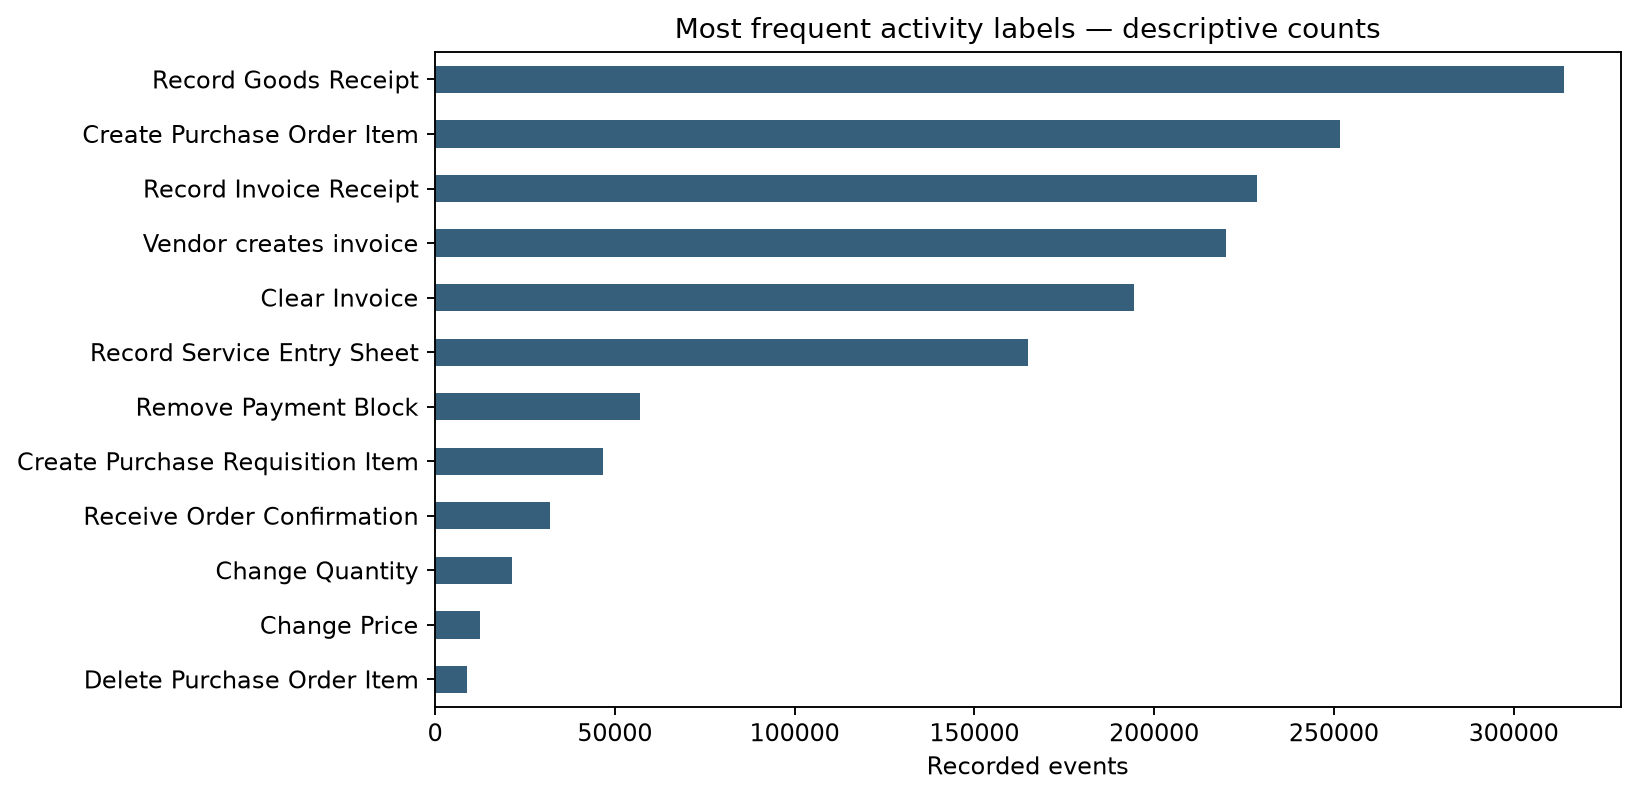

In [3]:
event_profile = pd.Series(
    {
        "events": len(events),
        "PO items": events[adapter.CASE].nunique(),
        "purchasing documents": events[adapter.DOC].nunique(),
        "activity labels": events[adapter.ACT].nunique(),
        "unparseable timestamps": int(events.timestamp.isna().sum()),
        "parsed minimum timestamp": str(events.timestamp.min()),
        "parsed maximum timestamp": str(events.timestamp.max()),
        "outside declared timing plausibility interval": int(
            (
                events.timestamp.notna()
                & (
                    ~events.timestamp.ge(pd.Timestamp(cfg["timing_plausibility_start"]))
                    | ~events.timestamp.lt(
                        pd.Timestamp(cfg["timing_plausibility_end_exclusive"])
                    )
                )
            ).sum()
        ),
        "events with unusable resource identity": int((~events.resource_usable).sum()),
    },
    name="Observed source profile",
)
table(event_profile, "event_log_profile")
outside_timing = events.timestamp.notna() & (
    ~events.timestamp.ge(pd.Timestamp(cfg["timing_plausibility_start"]))
    | ~events.timestamp.lt(pd.Timestamp(cfg["timing_plausibility_end_exclusive"]))
)
table(
    events.loc[
        outside_timing, ["eventID", adapter.CASE, adapter.ACT, adapter.TS]
    ].sort_values(adapter.TS),
    "source_rows_outside_timing_plausibility",
    rows=12,
)
report(
    f"{int(outside_timing.sum())} parsed timestamps lie outside the declared timing plausibility interval. "
    "These source rows remain in the event log and event counts. The adapter applies its plausibility "
    "rule to selected timing endpoints; it does not globally delete these events. The extreme dates "
    "must not be used as a certified extraction window."
)
activity = (
    events.groupby(adapter.ACT, observed=True)
    .agg(events=("eventID", "size"), PO_items=(adapter.CASE, "nunique"))
    .sort_values("events", ascending=False)
)
table(activity, "activity_profile", rows=len(activity))
fig, ax = plt.subplots(figsize=(9, 5))
activity.head(12).iloc[::-1]["events"].plot.barh(ax=ax, color="#365f7c")
ax.set(
    xlabel="Recorded events",
    ylabel="",
    title="Most frequent activity labels — descriptive counts",
)
figure(fig, "01_activity_profile")

### Evaluation questions

1. Can the declared assessment and relative priorities be reconstructed?
2. Can a priority be traced to recorded evidence and a specific question for business investigation?
3. How do perspectives and ranking policies change the investigation list?

The primary analysis fixes the norm, Balanced weights, flat scoring, company × spend-area grouping and case-count scaling. Perspective comparisons vary weights over the same prepared evidence. Ranking-policy comparisons hold Balanced scores and groups fixed. Numerical checks compare native and reference calculations on the same prepared assessments.

In [4]:
study_design = pd.DataFrame(
    [
        [
            "Primary application",
            "BPIC19; ten criteria; Balanced; flat; count; gamma=0",
            "Trace a priority into its evidence",
        ],
        [
            "Perspective comparison",
            "Same evidence and grouping; vary view weights",
            "Recompute scores and each view reference",
        ],
        [
            "Ranking-policy comparison",
            "Same Balanced scores and 30 groups; vary ranking rule",
            "Separate condition, volume and relative excess",
        ],
        [
            "Arithmetic verification",
            "Same prepared assessments; native vs reference calculations",
            "Check numerical consistency",
        ],
        [
            "Supplementary checks",
            "Separately labelled data diagnostics and parameter shifts",
            "Examine interpretation and assumption dependence",
        ],
    ],
    columns=["Analysis", "Design", "Purpose"],
).set_index("Analysis")
table(study_design, "evaluation_design")

,Design,Purpose
Analysis,,
Primary application,BPIC19; ten criteria; Balanced; flat; count; gamma=0,Trace a priority into its evidence
Perspective comparison,Same evidence and grouping; vary view weights,Recompute scores and each view reference
Ranking-policy comparison,Same Balanced scores and 30 groups; vary ranking rule,"Separate condition, volume and relative excess"
Arithmetic verification,Same prepared assessments; native vs reference calculations,Check numerical consistency
Supplementary checks,Separately labelled data diagnostics and parameter shifts,Examine interpretation and assumption dependence


## 2. Assessment specification

### Criteria, scope and evidence

The ten criteria are grouped into Completion, Timing, Rework and Effort proxy. They express researcher-defined screening choices, rather than elicited organisational policy. The catalogue below gives the full specification; C02 and C04 illustrate how a concern becomes an event-based check.

For an applicable non-consignment item, C02 records whether a clearing event is present. C04 independently selects the earliest parsed invoice-receipt and clearing timestamps, checks their plausibility and requires a non-negative interval. Its deviation is zero through 30 days and reaches one at 90 days. An invalid first endpoint is not replaced by a later endpoint. This interval does not match individual invoice cycles or represent a contractual due date.

Outside scope, unavailable evidence and an evaluated zero deviation remain distinct. Repeated events and resource-attributed records require interpretation before they can be described as avoidable work or labour time. The complete rules are in the [criterion configuration](../src/wise/evaluation/adapters/bpic2019.json).

,recorded condition,deviation scale,layer,scope,evidence,w(Balanced),w(Completion),w(Operations)
criterion,,,,,,,,
C01,No recorded invoice receipt,binary,Completion,non-consignment,"absence within recorded history, not proof of non-completion",1,3,1
C02,No recorded clearing,binary,Completion,non-consignment,"absence within recorded history, not proof of non-completion",1,3,1
C03,No recorded goods or service receipt,binary,Completion,DF1 or DF2,,1,3,1
C04,Long observed invoice-to-clearing lag,0 at 30; 1 at 90,Timing,non-consignment,both first timestamps observed and plausible; non-negative lag,1,2,1
C05,Invoice precedes goods or service receipt,binary,Timing,DF1,both first timestamps observed and plausible; equality permitted,1,2,1
C06,Invoice-receipt cancellation recorded,binary,Rework,all,,1,1,2
C07,Price or quantity edits recorded,0 at 0; 1 at 3,Rework,all,,1,1,2
C08,Repeated invoice receipt,0 at 1; 1 at 4,Rework,non-consignment,,1,1,2
C09,Recorded user-attributed events,0 at 5; 1 at 15,Effort proxy,all,every event resource usable; a missing or unusable event resource makes the full count unavailable,1,1,3


,Concern,Business scope,Recorded evidence,Assessment,Evidence distinction
Criterion,,,,,
C02,Completion,Non-consignment,Clear Invoice present or absent,1 if no clearing is recorded; 0 otherwise,Absence is assessed within recorded history
C04,Timing,Non-consignment,First parsed Record Invoice Receipt and Clear Invoice timestamps,0 through 30 days; linear ramp to 1 at 90 days,"Missing/invalid endpoints: unavailable, not zero"


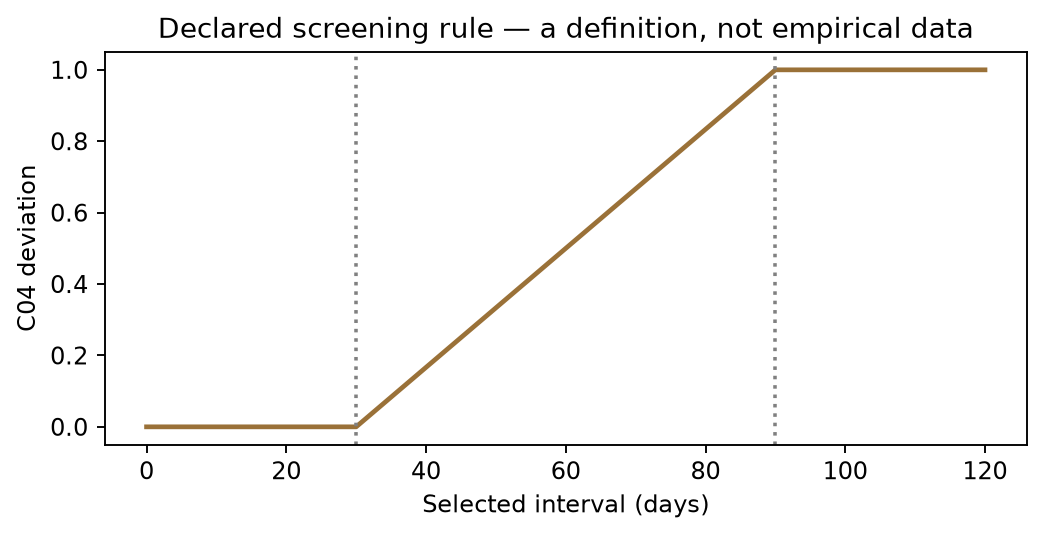

In [5]:
table(paper.table_b1(), "full_current_criterion_catalogue", rows=10)
mapping = pd.DataFrame(
    [
        [
            "C02",
            "Completion",
            "Non-consignment",
            "Clear Invoice present or absent",
            "1 if no clearing is recorded; 0 otherwise",
            "Absence is assessed within recorded history",
        ],
        [
            "C04",
            "Timing",
            "Non-consignment",
            "First parsed Record Invoice Receipt and Clear Invoice timestamps",
            "0 through 30 days; linear ramp to 1 at 90 days",
            "Missing/invalid endpoints: unavailable, not zero",
        ],
    ],
    columns=[
        "Criterion",
        "Concern",
        "Business scope",
        "Recorded evidence",
        "Assessment",
        "Evidence distinction",
    ],
).set_index("Criterion")
table(mapping, "T1_expectation_to_rule")
fig, ax = plt.subplots(figsize=(7, 3))
x = np.linspace(0, 120, 241)
ax.plot(x, np.clip((x - 30) / 60, 0, 1), color="#9a7138", lw=2)
ax.axvline(30, color="grey", ls=":")
ax.axvline(90, color="grey", ls=":")
ax.set(
    xlabel="Selected interval (days)",
    ylabel="C04 deviation",
    title="Declared screening rule — a definition, not empirical data",
)
figure(fig, "02_c04_rule_definition")

### Weights and comparison population

Balanced uses equal raw criterion weights. Flat scoring renormalises those weights over the criteria evaluable for each case; layers with more criteria therefore do not necessarily receive the same total weight as other layers. Completion and Operations change the emphasis on the same evidence.

The primary reference is the mean across all scored PO items under the selected view. Group priorities use scored-case counts with γ = 0. The γ = 20 adjustment is examined separately. Document grouping changes the aggregation unit while retaining PO-item assessments and the view-specific population reference. Ties follow the configuration shown below.

In [6]:
table(
    pd.DataFrame({v: adapter.weights_for(cfg, v) for v in cfg["views"]}),
    "raw_criterion_weights",
)
settings = pd.Series(
    {
        "configuration": cfg["id"],
        "status": cfg["evidence_status"],
        "primary scoring": cfg["primary_scoring_mode"],
        "reference": cfg["primary_reference"],
        "primary grouping": "company x spend area",
        "scale": "scored PO-item count",
        "primary gamma": cfg["primary_gamma"],
        "tie rule": cfg["tie_policy"],
    },
    name="Primary settings",
)
table(settings, "primary_settings")

,Balanced,Completion,Operations
C01,1.0,3.0,1.0
C02,1.0,3.0,1.0
C03,1.0,3.0,1.0
C04,1.0,2.0,1.0
C05,1.0,2.0,1.0
C06,1.0,1.0,2.0
C07,1.0,1.0,2.0
C08,1.0,1.0,2.0
C09,1.0,1.0,3.0
C10,1.0,1.0,3.0


,Primary settings
configuration,wise-bpic19-transparent-ten-v1
status,Researcher-defined illustrative configuration; not an elicited organisational policy
primary scoring,flat
reference,mean of all scored cases under the selected view
primary grouping,company x spend area
scale,scored PO-item count
primary gamma,0
tie rule,"descending Priority Index, then descending number of scored cases, then ascending group key"


### Case scores and evidence coverage

The assessment retains each criterion's scope, evidence state and deviation. A case can receive a score even when some applicable criteria lack usable evidence. Weighted evidence coverage reports the share of applicable weight that can be evaluated; it does not measure log completeness or conformity.

The following tables report flow populations, evidence states, scored cases and coverage by view and flow. Missing business labels remain explicit groups.

In [7]:
app = paper.application("bpic2019", DATA)
a, result = app.assessment, app.result
assert result.mode == "flat"
assert len(a.features) == events[adapter.CASE].nunique()
assert a.source["sha256"] == verified.loc["bpic2019", "sha256"]
flow = a.features["flow"].value_counts().to_frame("PO_items")
flow["share"] = flow.PO_items / len(a.features)
table(flow, "flow_case_counts")
table(
    a.features[["document", "flow", "group", "vendor", "n_events"]].head(10),
    "prepared_case_context",
    rows=10,
)
states = (
    pd.DataFrame({cid: a.state[cid].value_counts() for cid in a.state})
    .fillna(0)
    .astype(int)
    .T
)
states["in_scope"] = a.in_scope.sum()
states["evaluated_within_scope_share"] = a.severity.notna().sum() / states.in_scope
table(states, "criterion_evidence_states")
summary = pd.DataFrame(
    {
        "scored_cases": result.scores.notna().sum(),
        "mean_score": result.scores.mean(),
        "mean_weighted_coverage": pd.Series(
            {v: result.coverage(v).mean() for v in app.views}
        ),
    }
)
table(summary, "assessment_summary_by_view")
report(
    f"The native flat assessment produced scores for {result.scores.Balanced.notna().sum():,} "
    f"PO items and {a.groups.nunique()} company/spend-area groups. "
    f'Balanced mean weighted evidence coverage is {result.coverage("Balanced").mean():.4f}. '
    "Scoring every case does not mean every in-scope criterion has usable evidence."
)

,PO_items,share
flow,,
DF2,221010,0.877951
DF1,15182,0.060310
Consignment,14498,0.057593
2-way,1044,0.004147


,document,flow,group,vendor,n_events
case_id,,,,,
4507004931_00020,4507004931,DF2,companyID_0000 | Sales,vendorID_0670,10
4507004931_00010,4507004931,DF2,companyID_0000 | Sales,vendorID_0670,10
4507004931_00050,4507004931,DF2,companyID_0000 | Sales,vendorID_0670,10
4507004931_00040,4507004931,DF2,companyID_0000 | Sales,vendorID_0670,10
4507004931_00030,4507004931,DF2,companyID_0000 | Sales,vendorID_0670,10
4507014062_00050,4507014062,DF2,companyID_0000 | Trading & End Products,vendorID_0427,5
4507014062_00090,4507014062,DF2,companyID_0000 | Trading & End Products,vendorID_0427,5
4507014062_00080,4507014062,DF2,companyID_0000 | Trading & End Products,vendorID_0427,5
4507014062_00010,4507014062,DF2,companyID_0000 | Trading & End Products,vendorID_0427,5


,evaluated,invalid_temporal_evidence,missing_prerequisite,missing_resource_evidence,out_of_scope,in_scope,evaluated_within_scope_share
C01,237236,0,0,0,14498,237236,1.000000
C02,237236,0,0,0,14498,237236,1.000000
C03,236192,0,0,0,15542,236192,1.000000
C04,183269,24,53943,0,14498,237236,0.772518
C05,11128,0,4054,0,236552,15182,0.732973
C06,251734,0,0,0,0,251734,1.000000
C07,251734,0,0,0,0,251734,1.000000
C08,237236,0,0,0,14498,237236,1.000000
C09,38409,0,0,213325,0,251734,0.152578
C10,38409,0,0,213325,0,251734,0.152578


,scored_cases,mean_score,mean_weighted_coverage
Balanced,251734,0.898642,0.787570
Completion,251734,0.871766,0.866370
Operations,251734,0.926130,0.669052


The native flat assessment produced scores for 251,734 PO items and 30 company/spend-area groups. Balanced mean weighted evidence coverage is 0.7876. Scoring every case does not mean every in-scope criterion has usable evidence.

In [8]:
coverage_by_flow = pd.DataFrame(
    {v: result.coverage(v).groupby(a.features.flow).mean() for v in app.views}
)
table(coverage_by_flow, "coverage_by_flow")
state_by_flow = (
    pd.concat(
        {
            cid: pd.crosstab(a.features.flow, a.state[cid])
            for cid in ["C02", "C04", "C05", "C09"]
        },
        names=["criterion", "flow"],
    )
    .fillna(0)
    .astype(int)
)
table(state_by_flow, "selected_evidence_states_by_flow", rows=30)

,Balanced,Completion,Operations
flow,,,
2-way,0.746767,0.789567,0.689464
Consignment,1.000000,1.000000,1.000000
DF1,0.759406,0.831321,0.649573
DF2,0.775762,0.860374,0.648583


evaluated  out_of_scope  invalid_temporal_evidence  \
criterion flow                                                              
C02       2-way             1044             0                          0   
          Consignment          0         14498                          0   
          DF1              15182             0                          0   
          DF2             221010             0                          0   
C04       2-way              303             0                          0   
          Consignment          0         14498                          0   
          DF1               9667             0                          7   
          DF2             173299             0                         17   
C05       2-way                0          1044                          0   
          Consignment          0         14498                          0   
          DF1              11128             0                          0   
          DF2                  0        221010                          0   
C09       2-way              357             0                          0   
          Consignment      14498             0                          0   
          DF1               1703             0                          0   
          DF2              21851             0                          0   

                       missing_prerequisite  missing_resource_evidence  
criterion flow                                                          
C02       2-way                           0                          0  
          Consignment                     0                          0  
          DF1                             0                          0  
          DF2                             0                          0  
C04       2-way                         741                          0  
          Consignment                     0                          0  
          DF1                          5508                          0  
          DF2                         47694                          0  
C05       2-way                           0                          0  
          Consignment                     0                          0  
          DF1                          4054                          0  
          DF2                             0                          0  
C09       2-way                           0                        687  
          Consignment                     0                          0  
          DF1                             0                      13479  
          DF2                             0                     199159

## 3. Investigation priorities and supporting evidence

### Group priorities

For γ = 0 and case-count scaling, a group's Priority Index is its scored-case count multiplied by its positive mean-penalty excess over the scored-population mean. The table presents the mean, signed excess, scale and evidence coverage together.

The plot separates assessed condition from group size. Groups with a high mean penalty need not have the largest count-scaled excess. Packaging and Logistics are selected from the computed ranking for further investigation.

,rank,n_cases,mean_penalty,signed_mean_penalty_excess,PI,mean_coverage
assessment_group,,,,,,
companyID_0000 | Packaging,1,109199,0.117624,0.016266,1776.191040,0.788831
companyID_0000 | Logistics,2,5242,0.228143,0.126785,664.607179,0.706683
companyID_0000 | Trading & End Products,3,22292,0.112483,0.011125,247.991422,0.784027
companyID_0000 | (missing),4,3257,0.171639,0.070281,228.905428,0.793395
companyID_0003 | Real Estate,5,583,0.158235,0.056877,33.159176,0.762436
companyID_0003 | Others,6,241,0.194308,0.092950,22.401067,0.665456
companyID_0003 | Enterprise Services,7,122,0.205386,0.104029,12.691478,0.811475
companyID_0000 | Workforce Services,8,127,0.148257,0.046899,5.956215,0.790026
companyID_0003 | (missing),9,32,0.247321,0.145964,4.670833,0.816406


,rank,n_cases,mean_penalty,signed_mean_penalty_excess,PI,mean_coverage
assessment_group,,,,,,
companyID_0000 | Packaging,1,109199,0.117624,0.016266,1776.191040,0.788831
companyID_0000 | Logistics,2,5242,0.228143,0.126785,664.607179,0.706683


The all-scored-item reference mean penalty is 0.101357911. The first group is companyID_0000 | Packaging (PI 1,776.19); the second is companyID_0000 | Logistics (PI 664.61). The table exposes both mean deviation and scale, rather than treating the worst mean as the only ranking criterion.

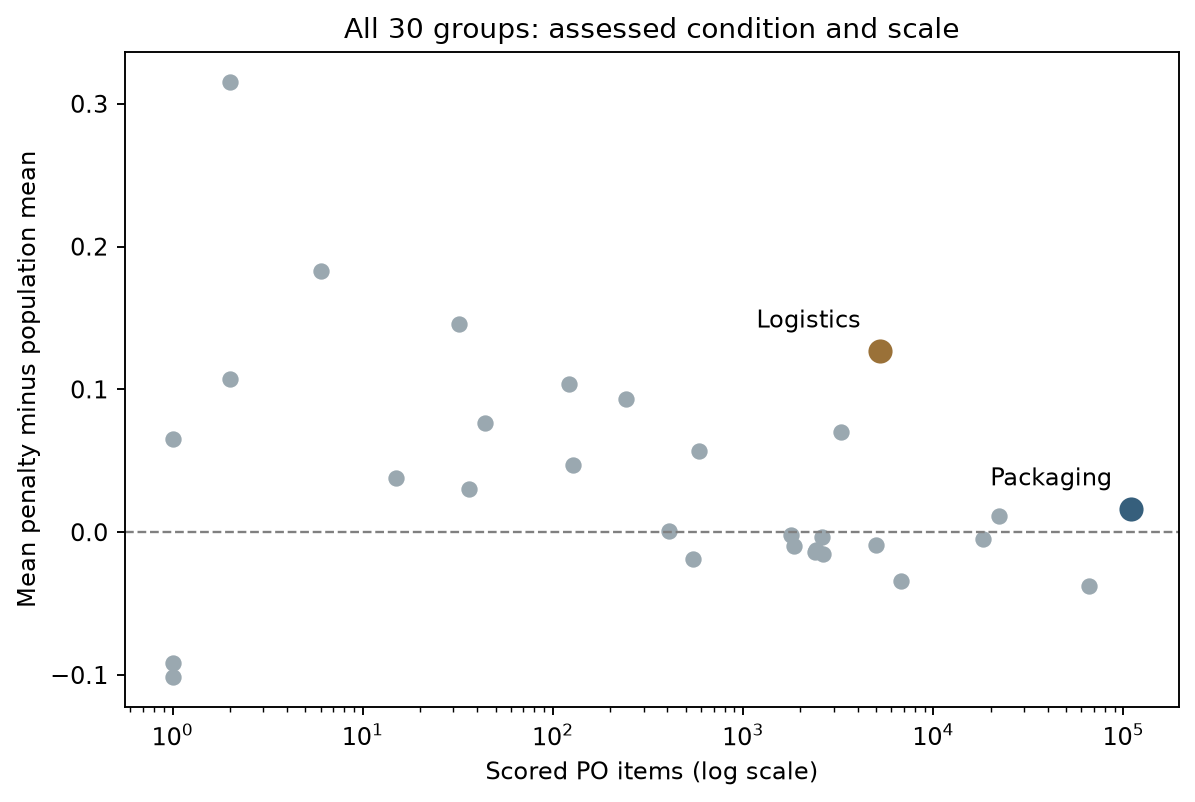

In [9]:
groups = app.backlog("Balanced").table.copy()
groups["rank"] = np.arange(1, len(groups) + 1)
groups["mean_penalty"] = 1 - groups.mean_score
groups["mean_coverage"] = result.coverage("Balanced").groupby(a.groups).mean()
reference_penalty = app.penalty("Balanced").mean()
groups["signed_mean_penalty_excess"] = groups.mean_penalty - reference_penalty
display_cols = [
    "rank",
    "n_cases",
    "mean_penalty",
    "signed_mean_penalty_excess",
    "PI",
    "mean_coverage",
]
table(groups[display_cols], "all_group_priorities", rows=30)
table(
    groups.loc[[paper.PACKAGING, paper.LOGISTICS], display_cols],
    "T2_selected_priorities",
)
report(
    f"The all-scored-item reference mean penalty is {reference_penalty:.9f}. "
    f"The first group is {groups.index[0]} (PI {groups.PI.iloc[0]:,.2f}); "
    f"the second is {groups.index[1]} (PI {groups.PI.iloc[1]:,.2f}). "
    "The table exposes both mean deviation and scale, rather than treating the worst mean as the only ranking criterion."
)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(groups.n_cases, groups.signed_mean_penalty_excess, c="#9aa8b0", s=35)
for group, colour in [(paper.PACKAGING, "#365f7c"), (paper.LOGISTICS, "#9a7138")]:
    row = groups.loc[group]
    ax.scatter(row.n_cases, row.signed_mean_penalty_excess, c=colour, s=85)
    ax.annotate(
        group.split(" | ")[-1],
        (row.n_cases, row.signed_mean_penalty_excess),
        xytext=(-8, 10),
        textcoords="offset points",
        ha="right",
    )
ax.axhline(0, color="grey", ls="--", lw=1)
ax.set_xscale("log")
ax.set(
    xlabel="Scored PO items (log scale)",
    ylabel="Mean penalty minus population mean",
    title="All 30 groups: assessed condition and scale",
)
figure(fig, "03_group_gap_volume")

### Signed contributions

Layer contributions attribute each group's aggregate penalty gap to its assessed concerns. Negative contributions offset positive ones before the total is clipped at zero. They must remain visible when explaining the priority.

The criterion-level decomposition separates C04 from C05 within Timing and checks that criterion sums reproduce both the native layer contributions and the group Priority Index. Evidence-state counts provide the denominators for interpreting these contributions. The decomposition is an arithmetic attribution, not a causal explanation.

,Completion,Timing,Rework,Effort proxy,sum,Priority Index
companyID_0000 / Packaging,-332.420985,2365.436368,-267.950108,11.125766,1776.191040,1776.191040
companyID_0000 / Logistics,811.132774,-154.248298,10.535362,-2.812658,664.607179,664.607179


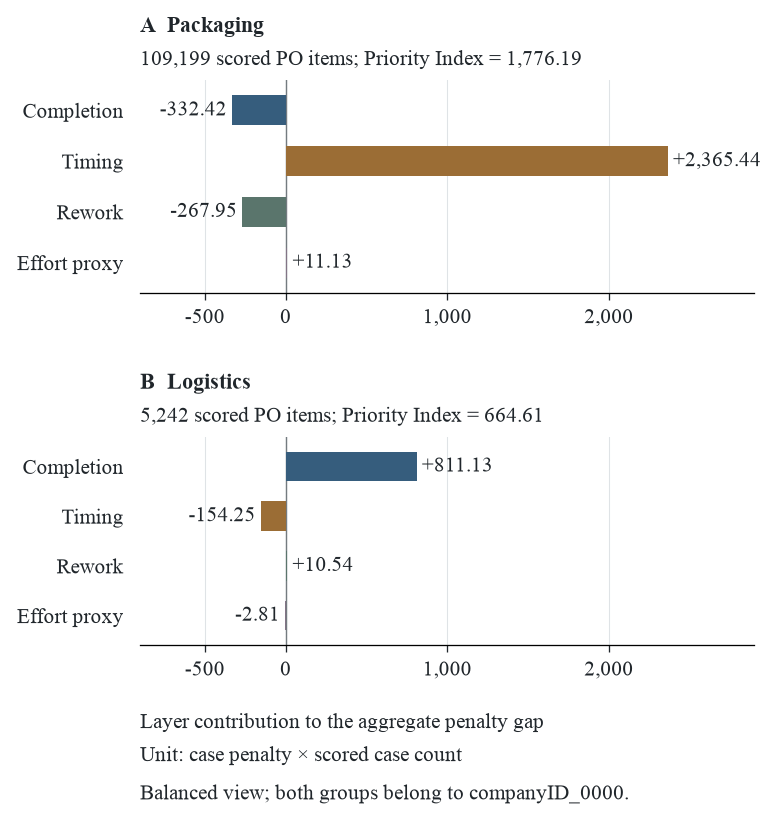

,C01,C02,C03,C04,C05,C06,C07,C08,C09,C10
assessment_group,,,,,,,,,,
companyID_0000 | Packaging,-419.338854,193.044196,-106.126328,2365.436368,0.0,-186.719924,-39.159003,-42.071182,0.707672,10.418093
companyID_0000 | Logistics,445.659723,384.336125,-18.863074,-154.248298,0.0,-0.244207,-20.089952,30.869520,1.078337,-3.890995
companyID_0000 | Trading & End Products,135.747674,30.717173,168.194082,-395.131398,0.0,88.803248,204.114219,25.688132,0.344473,-10.486180
companyID_0000 | (missing),83.170635,123.215895,56.832302,-52.068863,0.0,-6.685864,23.780922,-2.712595,0.106575,3.266421
companyID_0003 | Real Estate,22.034102,41.718549,-4.475162,-20.048609,0.0,-1.481562,-3.250930,-1.036862,0.215808,-0.516158
companyID_0003 | Others,0.623261,34.276352,-1.849938,-8.315996,0.0,-0.221366,-1.471422,-0.409368,-0.017087,-0.213369
companyID_0003 | Enterprise Services,9.220074,10.219564,-0.936483,-4.346232,0.0,-0.449544,-0.778618,-0.263479,0.134207,-0.108012
companyID_0000 | Workforce Services,1.212505,-0.006761,1.525136,-4.069893,0.0,1.799890,1.276773,4.315008,0.015996,-0.112439
companyID_0003 | (missing),2.856319,3.479136,-0.245635,-1.139995,0.0,-0.117913,-0.204228,-0.069109,0.140588,-0.028331


,C04,C05,Timing sum
assessment_group,,,
companyID_0000 | Packaging,2365.436368,0.0,2365.436368
companyID_0000 | Logistics,-154.248298,0.0,-154.248298


all_group_items  in_scope  out_of_scope  \
group                      criterion                                            
companyID_0000 | Packaging C04                 109199    100635          8564   
                           C05                 109199      4332        104867   
companyID_0000 | Logistics C04                   5242      5242             0   
                           C05                   5242      4602           640   

                                      unavailable_in_scope  evaluated_zero  \
group                      criterion                                         
companyID_0000 | Packaging C04                       24027           12540   
                           C05                         394            3938   
companyID_0000 | Logistics C04                        3508            1073   
                           C05                        2777            1825   

                                      evaluated_positive  
group                      criterion                      
companyID_0000 | Packaging C04                     64068  
                           C05                         0  
companyID_0000 | Logistics C04                       661  
                           C05                         0

Packaging’s signed Timing contribution is 2,365.436368: C04 contributes 2,365.436368, while C05 contributes 0.000000. These are count-scaled differences from the same population reference. The criterion and layer sums were checked against the native priority calculation.

In [10]:
layers = paper.item_17_layer_contributions(DATA)
table(layers, "signed_layer_contributions")
figure(paper.figure_4(DATA), "04_signed_layer_contributions")
criteria_signed = criterion_contributions(app)
table(criteria_signed, "signed_criterion_contributions_all_groups", rows=30)
timing = criteria_signed.loc[[paper.PACKAGING, paper.LOGISTICS], ["C04", "C05"]].copy()
timing["Timing sum"] = timing.sum(axis=1)
table(timing, "C04_C05_timing_reconciliation")
focal_states = []
for group in [paper.PACKAGING, paper.LOGISTICS]:
    members = a.groups.eq(group)
    for cid in ["C04", "C05"]:
        values, scope = a.severity.loc[members, cid], a.in_scope.loc[members, cid]
        focal_states.append(
            {
                "group": group,
                "criterion": cid,
                "all_group_items": int(members.sum()),
                "in_scope": int(scope.sum()),
                "out_of_scope": int((~scope).sum()),
                "unavailable_in_scope": int((scope & values.isna()).sum()),
                "evaluated_zero": int(values.eq(0).sum()),
                "evaluated_positive": int(values.gt(0).sum()),
            }
        )
table(
    pd.DataFrame(focal_states).set_index(["group", "criterion"]),
    "focal_timing_evidence_denominators",
)
report(
    f'Packaging’s signed Timing contribution is {timing.loc[paper.PACKAGING,"Timing sum"]:,.6f}: '
    f'C04 contributes {timing.loc[paper.PACKAGING,"C04"]:,.6f}, while C05 contributes '
    f'{timing.loc[paper.PACKAGING,"C05"]:,.6f}. These are count-scaled differences from the same '
    "population reference. The criterion and layer sums were checked against the native priority calculation."
)

### Packaging: invoice-to-clearing intervals

The C04 comparison includes only items with evaluable selected endpoints. Its ECDF displays the full interval distribution for Packaging and the remaining groups. A second comparison restricts both populations to DF2, addressing one observed difference in flow composition.

The DF2 comparison is descriptive rather than a complete case-mix adjustment. The interval follows the declared first-endpoint rule; it cannot establish payment lateness without contractual and invoice-level information.

,applicable,usable endpoints
companyID_0000 / Logistics,5242,1734
companyID_0000 / Packaging,100635,76608


,n,median_days
Packaging,76608,69.040972
Remaining groups,106661,28.929167


,n,median_days
Packaging,73157,70.139583
Remaining groups,100142,29.101389


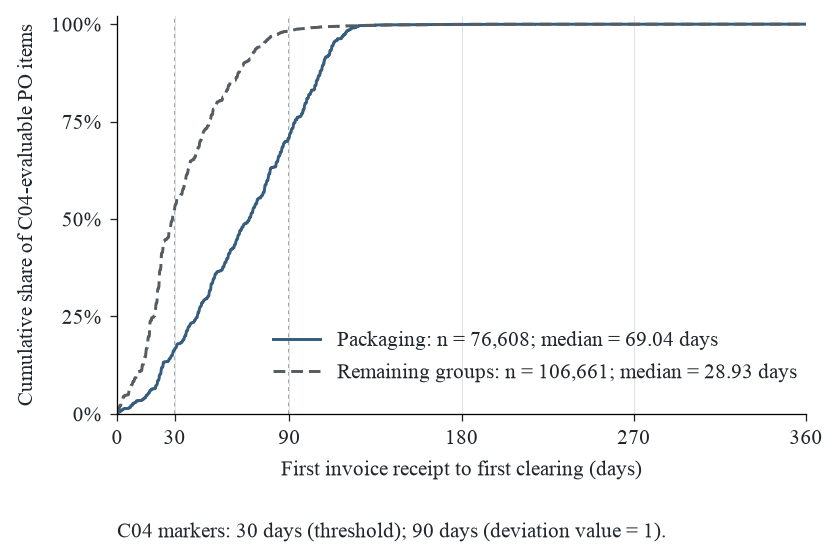

Among C04-evaluable items, the median selected interval is 69.04 days in Packaging and 28.93 days outside Packaging. Within DF2, the medians are 70.14 and 29.10 days. This is a descriptive stratum check, not a full adjustment for case mix.

In [11]:
table(paper.item_35_c04_endpoints(DATA), "C04_applicability_and_evaluability")
table(paper.item_09_lag_medians(DATA), "C04_interval_summary")
table(paper.item_10_lag_medians_df2(DATA), "C04_interval_summary_DF2")
figure(paper.figure_5(DATA), "05_C04_interval_ECDF")
lags = paper.item_09_lag_medians(DATA)
df2_lags = paper.item_10_lag_medians_df2(DATA)
report(
    f'Among C04-evaluable items, the median selected interval is {lags.loc["Packaging","median_days"]:.2f} '
    f'days in Packaging and {lags.loc["Remaining groups","median_days"]:.2f} days outside Packaging. '
    f'Within DF2, the medians are {df2_lags.loc["Packaging","median_days"]:.2f} and '
    f'{df2_lags.loc["Remaining groups","median_days"]:.2f} days. '
    "This is a descriptive stratum check, not a full adjustment for case mix."
)

### One assessment traced to source records

Among Packaging items with a positive C04 deviation, the worked item minimises the distance to the median interval across all C04-evaluable Packaging items. Ties are resolved by ascending item identifier. Its original event rows reconstruct the C04 endpoints, interval and deviation. The table also shows all prepared criterion states, effective weights and penalty contributions for that item.

The C04 calculation is checked against source records; the sum of prepared criterion contributions is checked against the native case score. The timeline preserves event identifiers so the calculation can be inspected.

,worked PO item
item,4507005472_00040
first_invoice_receipt,2018-02-16 10:15
first_clearing,2018-04-26 11:14
lag_days,69.040972
deviation,0.650683
evaluable_criteria,7
contribution,0.092955
other_nonzero,0
state.C05,out_of_scope
state.C09,missing_resource_evidence


,eventID,event concept:name,event time:timestamp,event org:resource,timestamp
53067,72782515798016,Create Purchase Order Item,25-01-2018 16:01:00.000,user_147,2018-01-25 16:01:00
120985,72782515798017,Record Goods Receipt,14-02-2018 17:55:00.000,batch_06,2018-02-14 17:55:00
122068,72782515798018,Vendor creates invoice,14-02-2018 23:59:00.000,NONE,2018-02-14 23:59:00
128887,72782515798019,Record Invoice Receipt,16-02-2018 10:15:00.000,user_004,2018-02-16 10:15:00
431386,72782515798020,Clear Invoice,26-04-2018 11:14:00.000,user_002,2018-04-26 11:14:00


,layer,raw_quantity,in_scope,evidence_state,deviation,effective_Balanced_weight,penalty_contribution
C01,Completion,0.000000,True,evaluated,0.000000,0.142857,0.000000
C02,Completion,0.000000,True,evaluated,0.000000,0.142857,0.000000
C03,Completion,0.000000,True,evaluated,0.000000,0.142857,0.000000
C04,Timing,69.040972,True,evaluated,0.650683,0.142857,0.092955
C05,Timing,1.680556,False,out_of_scope,NaN,0.000000,0.000000
C06,Rework,0.000000,True,evaluated,0.000000,0.142857,0.000000
C07,Rework,0.000000,True,evaluated,0.000000,0.142857,0.000000
C08,Rework,1.000000,True,evaluated,0.000000,0.142857,0.000000
C09,Effort proxy,3.000000,True,missing_resource_evidence,NaN,0.000000,0.000000
C10,Effort proxy,3.000000,True,missing_resource_evidence,NaN,0.000000,0.000000


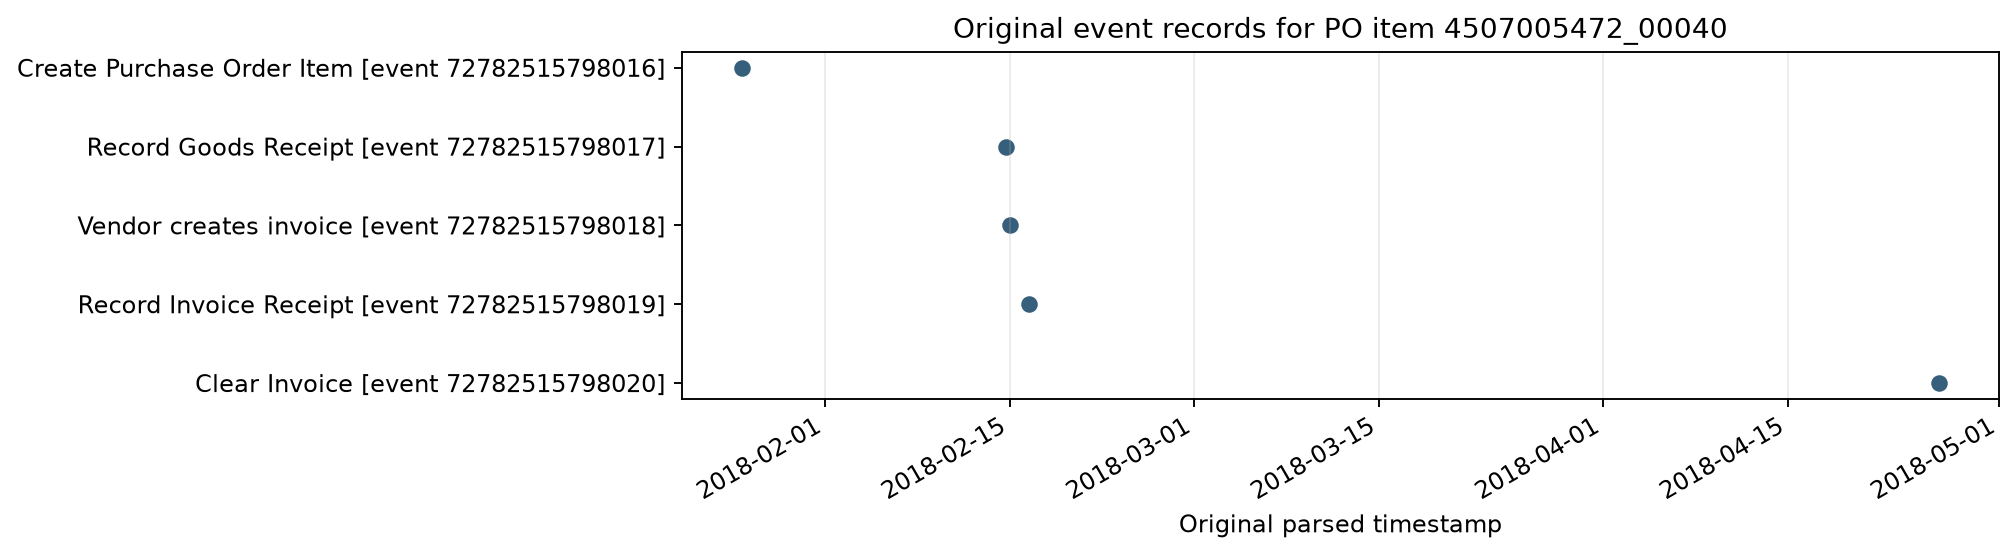

The original rows reconstruct an interval of 69.040972 days and C04 deviation 0.650683. The prepared criterion contributions reconcile with the native case score 0.907045; weighted coverage is 0.777778. Among positive-C04 Packaging items, the example minimises distance to the median across all evaluable Packaging intervals; ties use ascending item identifier.

In [12]:
worked = paper.item_12_worked_po_item(DATA)
case_id = worked["item"]
trace = events.loc[
    events[adapter.CASE].eq(case_id), adapter.COLS + ["timestamp"]
].copy()
trace = trace.sort_values(
    ["timestamp", "eventID"], kind="mergesort", na_position="last"
)
table(worked, "worked_item_calculation")
table(
    trace[["eventID", adapter.ACT, adapter.TS, adapter.RESOURCE, "timestamp"]],
    "worked_item_original_events",
    rows=len(trace),
)
case_assessment = pd.DataFrame(
    {
        "layer": pd.Series(a.layers),
        "raw_quantity": a.raw.loc[case_id],
        "in_scope": a.in_scope.loc[case_id],
        "evidence_state": a.state.loc[case_id],
        "deviation": a.severity.loc[case_id],
        "effective_Balanced_weight": result.effective_weights("Balanced").loc[case_id],
        "penalty_contribution": result.penalties("Balanced").loc[case_id],
    }
)
table(case_assessment, "T3_worked_item_all_criteria", rows=10)
invoice_ts = trace.loc[
    trace[adapter.ACT].eq("Record Invoice Receipt"), "timestamp"
].min()
clear_ts = trace.loc[trace[adapter.ACT].eq("Clear Invoice"), "timestamp"].min()
actual_days = (clear_ts - invoice_ts).total_seconds() / 86400
assert np.isclose(actual_days, float(worked["lag_days"]), atol=1e-12, rtol=0)
assert invoice_ts >= pd.Timestamp(
    cfg["timing_plausibility_start"]
) and invoice_ts < pd.Timestamp(cfg["timing_plausibility_end_exclusive"])
assert clear_ts >= pd.Timestamp(
    cfg["timing_plausibility_start"]
) and clear_ts < pd.Timestamp(cfg["timing_plausibility_end_exclusive"])
assert actual_days >= 0
rule_c04 = next(rule for rule in cfg["criteria"] if rule["id"] == "C04")
source_c04_deviation = np.clip(
    (actual_days - rule_c04["threshold"]) / rule_c04["width"], 0, 1
)
assert np.isclose(
    source_c04_deviation, a.severity.loc[case_id, "C04"], atol=1e-12, rtol=0
)
assert np.isclose(
    case_assessment.penalty_contribution.sum(),
    1 - result.scores.loc[case_id, "Balanced"],
    atol=1e-12,
)
fig, ax = plt.subplots(figsize=(10, max(3, len(trace) * 0.35)))
dated = trace[trace.timestamp.notna()].copy()
ax.scatter(dated.timestamp, np.arange(len(dated)), color="#365f7c")
ax.set_yticks(
    np.arange(len(dated)),
    [f"{act} [event {eid}]" for act, eid in zip(dated[adapter.ACT], dated.eventID)],
)
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.25)
ax.set(
    xlabel="Original parsed timestamp",
    title=f"Original event records for PO item {case_id}",
)
fig.autofmt_xdate()
figure(fig, "06_worked_item_source_timeline")
report(
    f"The original rows reconstruct an interval of {actual_days:.6f} days and C04 deviation "
    f"{source_c04_deviation:.6f}. The prepared criterion contributions reconcile with the native case score "
    f'{float(worked["score"]):.6f}; weighted coverage is {float(worked["coverage"]):.6f}. '
    "Among positive-C04 Packaging items, the example minimises distance to the median across all evaluable Packaging intervals; ties use ascending item identifier."
)

### Logistics: recorded absences and timing availability

Logistics has a different evidence pattern. The cross-tabulation shows joint absence of invoice-receipt and clearing records, first for all group items and then for the items to which both absence criteria apply. Separate evidence-state counts show how many items support a C04 interval.

A low Timing contribution can coexist with limited timing evidence. Missing records do not establish which obligations were due, cancelled, open or recorded in another system.

In [13]:
logistics = a.groups.eq(paper.LOGISTICS)
lf = a.features.loc[logistics]
joint_absences = pd.crosstab(
    lf.n_invoice.eq(0).rename("No invoice receipt"),
    lf.n_clear.eq(0).rename("No clearing"),
    dropna=False,
)
table(joint_absences, "logistics_joint_recorded_absences")
applicable_absence = logistics & a.in_scope.C01 & a.in_scope.C02
lf_applicable = a.features.loc[applicable_absence]
table(
    pd.crosstab(
        lf_applicable.n_invoice.eq(0).rename("No invoice receipt"),
        lf_applicable.n_clear.eq(0).rename("No clearing"),
        dropna=False,
    ),
    "logistics_joint_absences_applicable_items",
)
table(
    pd.Series(
        {
            "all_group_items": int(logistics.sum()),
            "C01_C02_applicable_items": int(applicable_absence.sum()),
            "outside_absence_rule_scope": int(
                logistics.sum() - applicable_absence.sum()
            ),
        },
        name="Denominators",
    ),
    "logistics_absence_scope_denominators",
)
logistics_states = (
    pd.DataFrame(
        {c: a.state.loc[logistics, c].value_counts() for c in ["C01", "C02", "C04"]}
    )
    .fillna(0)
    .astype(int)
)
table(logistics_states, "logistics_evidence_states")
clearing_missing = int(lf.n_clear.eq(0).sum())
evaluable_timing = int(a.state.loc[logistics, "C04"].eq(EVALUATED).sum())
report(
    f"{clearing_missing:,} of {len(lf):,} Logistics items ({clearing_missing/len(lf):.1%}) have no "
    f"recorded clearing; {evaluable_timing:,} have evaluable C04 timing. The cross-tab shows the overlap "
    f"between invoice and clearing absence. Separately, {int(lf_applicable.n_clear.eq(0).sum()):,} "
    f"of {len(lf_applicable):,} C01/C02-applicable items have no recorded clearing. "
    "Missing-record counts do not establish which obligations were due."
)

No clearing,False,True
No invoice receipt,,
False,1735,247
True,0,3260


No clearing,False,True
No invoice receipt,,
False,1735,247
True,0,3260


,Denominators
all_group_items,5242
C01_C02_applicable_items,5242
outside_absence_rule_scope,0


,C01,C02,C04
evaluated,5242,5242,1734
invalid_temporal_evidence,0,0,1
missing_prerequisite,0,0,3507


3,507 of 5,242 Logistics items (66.9%) have no recorded clearing; 1,734 have evaluable C04 timing. The cross-tab shows the overlap between invoice and clearing absence. Separately, 3,507 of 5,242 C01/C02-applicable items have no recorded clearing. Missing-record counts do not establish which obligations were due.

### Questions for business investigation

The two groups lead to different requests for further evidence. Packaging motivates checking payment terms, disputes and endpoint meanings. Logistics motivates checking obligation status and reconciling absent records against source systems.

The table separates the observed finding from possible explanations and the evidence needed to examine them. Priorities support choosing records to inspect; they do not quantify financial loss, attainable savings or intervention effects.

In [14]:
review_questions = pd.DataFrame(
    [
        [
            "Packaging",
            "Positive Timing contribution; longer selected C04 intervals",
            "Payment terms, disputes, case mix, meaning of clearing and selected endpoints",
            "Matched invoice/receipt/payment records and domain review",
        ],
        [
            "Logistics",
            "Positive Completion contribution; missing recorded invoice/clearing",
            "Open/future/cancelled obligations, records held elsewhere, observation completeness",
            "Obligation status and reconciliation against source systems",
        ],
    ],
    columns=[
        "Group",
        "Observed route into review",
        "Questions, not established causes",
        "Further evidence needed",
    ],
).set_index("Group")
table(review_questions, "business_review_questions")

,Observed route into review,"Questions, not established causes",Further evidence needed
Group,,,
Packaging,Positive Timing contribution; longer selected C04 intervals,"Payment terms, disputes, case mix, meaning of clearing and selected endpoints",Matched invoice/receipt/payment records and domain review
Logistics,Positive Completion contribution; missing recorded invoice/clearing,"Open/future/cancelled obligations, records held elsewhere, observation completeness",Obligation status and reconciliation against source systems


## 4. Perspectives and ranking policies

### Perspective-dependent review lists

Balanced, Completion and Operations reuse the same criterion evidence but change raw weights. Each view recomputes effective weights, scores, coverage and its population reference. The following comparison reports the first groups and the top 20 positive-priority purchasing documents.

Group-level ordering and document-level membership are separate outcomes. Stable leading groups can still produce different document shortlists. All comparisons use the declared capacity and deterministic tie policy.

In [15]:
table(paper.item_22_first_two_slices(DATA), "top_groups_by_view")
doc_lists = {v: paper.document_shortlist(DATA, v, 20)[0] for v in app.views}
document_ranks = pd.DataFrame(
    {
        v: pd.Series(lst, index=np.arange(1, len(lst) + 1))
        for v, lst in doc_lists.items()
    }
)
document_ranks.index.name = "Rank in positive-PI document list"
table(document_ranks, "document_top20_ranks", rows=20)
table(paper.item_21_document_shortlists(DATA), "document_top20_membership_overlap")
report(
    "The first purchasing document is "
    + "; ".join(f"{v}: {lst[0]}" for v, lst in doc_lists.items())
    + ". Group stability and changed document selection are separate observations at different aggregation levels."
)
for view in app.views:
    app.backlog(view).table.to_csv(OUT / "tables" / f"group_ranking_{view}.csv")
    app.backlog(view, by="document").table.to_csv(
        OUT / "tables" / f"document_ranking_{view}.csv.gz", compression="gzip"
    )

,first,PI first,second,PI second
view,,,,
Balanced,companyID_0000 / Packaging,1776.191040,companyID_0000 / Logistics,664.607179
Completion,companyID_0000 / Packaging,1636.727524,companyID_0000 / Logistics,1070.670971
Operations,companyID_0000 / Packaging,1134.709340,companyID_0000 / Logistics,446.286369


,Balanced,Completion,Operations
Rank in positive-PI document list,,,
1,4508073932,4508073932,4507021416
2,4507021416,4507021416,4508073932
3,4507039623,4507039623,4507032314
4,4508055697,4508055697,4507007248
5,4508045845,4508045845,4507021136
6,4507018973,4508044035,4507030241
7,4508072993,4507018973,4508071619
8,4507015778,4508072993,4507039623
9,4508044035,4507015778,4508062388


,shared,distinct,jaccard,length_first,length_second,tie_across_cut
views,,,,,,
Balanced / Completion,18,22,0.818182,20,20,False
Balanced / Operations,10,30,0.333333,20,20,False
Completion / Operations,8,32,0.250000,20,20,False


The first purchasing document is Balanced: 4508073932; Completion: 4508073932; Operations: 4507021416. Group stability and changed document selection are separate observations at different aggregation levels.

### Ranking-policy comparison

This comparison fixes Balanced case penalties, the scored population and the company × spend-area groups. Mean penalty represents assessed condition; total penalty combines assessed deviation and volume; PI measures count-scaled excess over the population reference. The γ = 20 policy applies the declared small-group adjustment.

Top-ten overlap uses all ranked groups, including zero-priority ties, following the paper's policy comparison. The components and complete order are reported so membership overlap does not obscure changes in position.

,n_cases,mean_penalty,total_penalty,PI,PI_gamma20
assessment_group,,,,,
companyID_0000 | Packaging,109199,0.117624,12844.373559,1776.191040,1775.865787
companyID_0000 | Logistics,5242,0.228143,1195.925348,664.607179,662.081116
companyID_0000 | Trading & End Products,22292,0.112483,2507.461974,247.991422,247.769128
companyID_0000 | (missing),3257,0.171639,559.028144,228.905428,227.508386
companyID_0003 | Real Estate,583,0.158235,92.250838,33.159176,32.059369
companyID_0003 | Others,241,0.194308,46.828323,22.401067,20.684510
companyID_0003 | Enterprise Services,122,0.205386,25.057143,12.691478,10.903946
companyID_0000 | Workforce Services,127,0.148257,18.828669,5.956215,5.145845
companyID_0003 | (missing),32,0.247321,7.914286,4.670833,2.874359


,PI,mean_penalty,total_penalty,PI_gamma20
Rank,,,,
1,companyID_0000 | Packaging,companyID_0002 | Marketing,companyID_0000 | Packaging,companyID_0000 | Packaging
2,companyID_0000 | Logistics,companyID_0003 | Sales,companyID_0000 | Sales,companyID_0000 | Logistics
3,companyID_0000 | Trading & End Products,companyID_0003 | (missing),companyID_0000 | Trading & End Products,companyID_0000 | Trading & End Products
4,companyID_0000 | (missing),companyID_0000 | Logistics,companyID_0000 | Additives,companyID_0000 | (missing)
5,companyID_0003 | Real Estate,companyID_0001 | Sales,companyID_0000 | Logistics,companyID_0003 | Real Estate
6,companyID_0003 | Others,companyID_0003 | Enterprise Services,companyID_0000 | (missing),companyID_0003 | Others
7,companyID_0003 | Enterprise Services,companyID_0003 | Others,companyID_0000 | Latex & Monomers,companyID_0003 | Enterprise Services
8,companyID_0000 | Workforce Services,companyID_0003 | CAPEX & SOCS,companyID_0000 | CAPEX & SOCS,companyID_0000 | Workforce Services
9,companyID_0003 | (missing),companyID_0000 | (missing),companyID_0000 | Pigments & Colorants,companyID_0003 | (missing)


,shared with the primary PI top ten
mean_penalty,6
total_penalty,4
gamma20,10


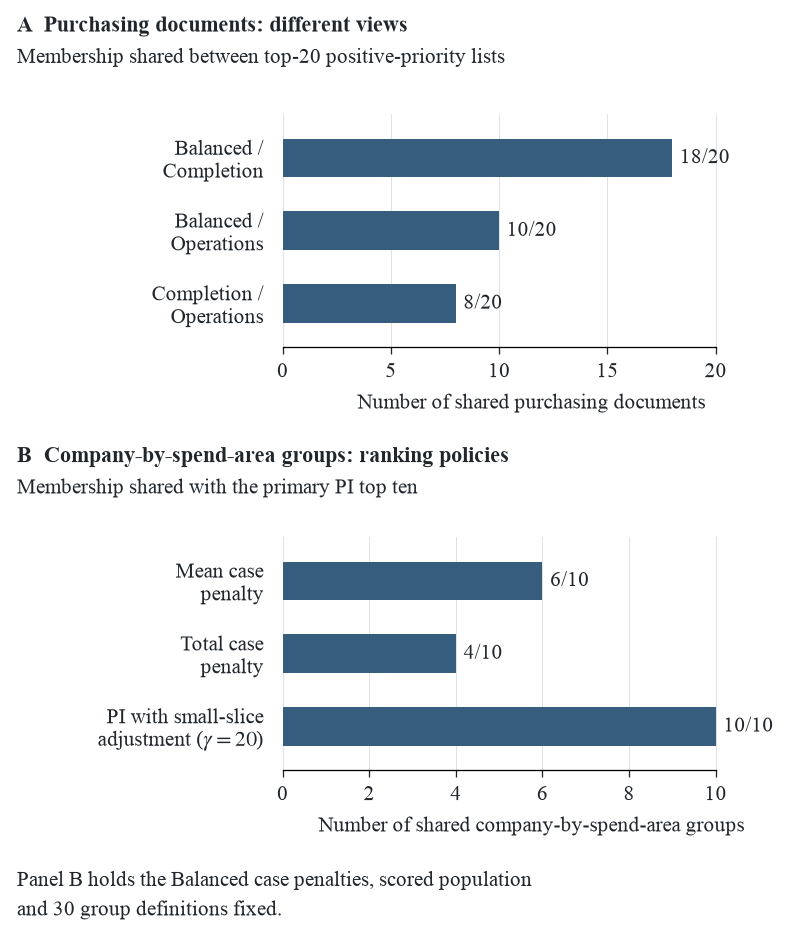

In [16]:
policies = paper.ranking_policies(DATA)
table(policies, "ranking_policy_components", rows=30)
policy_order = pd.DataFrame(
    {
        c: pd.Series(ordered(policies, c).index[:10], index=np.arange(1, 11))
        for c in ["PI", "mean_penalty", "total_penalty", "PI_gamma20"]
    }
)
policy_order.index.name = "Rank"
table(policy_order, "ranking_policy_top10_order", rows=10)
table(paper.item_24_ranking_policies(DATA), "ranking_policy_top10_overlap")
figure(paper.figure_6(DATA), "07_view_and_policy_shortlists")

## 5. Verification and further applications

### Numerical consistency

Native and reference calculations are compared for three views in each of three applications, two scoring modes and γ values of 0 and 20. Numerical agreement uses tolerance 1e−8; scope and evidence states must agree exactly. Additional checks cover case-record order, norm serialisation and attached whole-case context.

These checks start from the same prepared criterion assessments. They test calculation and alignment rather than independently validating every adapter's event interpretation. The original-row reconstruction above separately checks the worked C04 measurement.

The following cells load the two secondary datasets, compare the Section V results with the package's printed-value catalogue and save calculation records. A missing source or a failed comparison stops execution. Reported residuals are computed in the current numerical environment.

In [17]:
consistency = paper.item_33_consistency_check(DATA)
table(consistency, "native_reference_consistency")
assert bool(consistency["below tolerance"])
assert bool(consistency["scope and evidence states identical"])
additional_checks = paper.further_checks(DATA)
assert additional_checks["scores preserved"].all()
assert additional_checks["norm fingerprint unchanged"].all()
table(additional_checks, "serialisation_reordering_context_checks")
eval_items = [i for i in paper.ITEMS if i not in (1, 2, 41, 42)]
comparison = paper.compare(DATA, items=eval_items)
table(paper.summary(comparison), "paper_item_reproduction_summary", rows=40)
comparison.to_csv(OUT / "tables" / "paper_values_computed_vs_printed.csv", index=False)
differences = comparison.loc[comparison.status.ne("agrees")]
table(differences, "paper_value_discrepancies", rows=50)
assert comparison.status.eq(
    "agrees"
).all(), "A paper result differs or was not computed."
report(
    f'{int(comparison.status.eq("agrees").sum())} of {len(comparison)} compared printed values agree '
    f"under the package’s declared rounding/order-of-magnitude checks; {len(differences)} differ. "
    f'The largest native/reference residual is {float(consistency["largest absolute difference"]):.3e}, '
    f'against tolerance {float(consistency["declared tolerance"]):.1e}. '
    "These are checks of arithmetic on the same prepared assessments, not independent event-semantic validation."
)
for name in ["bpic2019", "bpic2013_incidents", "bpic2017"]:
    record = paper.calculation_record(name, DATA)
    (OUT / "provenance" / f"{name}_calculation_record.json").write_text(
        json.dumps(record, indent=2) + "\n"
    )

,consistency check
applications,3
views per application,3
primary view evaluations,9
scoring modes,2
mode-view combinations,18
each checked at γ,0 and 20
largest absolute difference,0.0
declared tolerance,0.0
below tolerance,True
scope and evidence states identical,True


,cases reordered,norm serialised and read back,whole-case context attached,context,norm fingerprint unchanged,scores preserved
bpic2019,0.0,0.0,0.0,"document, vendor, flow",True,True
bpic2013_incidents,0.0,0.0,0.0,product_group,True,True
bpic2017,0.0,0.0,0.0,"application_type, loan_goal",True,True


,place,title,kind,values,agree,differ,not_computed,agrees
item,,,,,,,,
3,"Section 5.1, p. 27; Appendix B.1, p. 37",Size of the BPIC'19 export,result,3,3,0,0,True
4,"Appendix B.1, p. 37",Matching flows of the purchase-order items,result,4,4,0,0,True
5,"Section 5.1, p. 27; Appendix B.1, p. 37",Company-by-spend-area groups,result,1,1,0,0,True
6,"Section 5.1, p. 28; Appendix B.1, p. 38",All purchase-order items receive a score under the primary flat assessment,result,3,3,0,0,True
7,"Section 5.1, p. 28",Mean weighted coverage per view,result,3,3,0,0,True
8,"Section 5.3, p. 29",C04 in Packaging,result,2,2,0,0,True
9,"Section 5.3, p. 29",Median selected invoice-to-clearing interval,result,4,4,0,0,True
10,"Section 5.3, p. 29",The same medians within the DF2 flow,result,2,2,0,0,True
11,"Fig. 5, p. 30","Empirical cumulative distributions of the selected invoice-to-clearing interval, Packaging and r...",figure,6,6,0,0,True


,item,place,quantity,printed,computed,agrees,status,note


168 of 168 compared printed values agree under the package’s declared rounding/order-of-magnitude checks; 0 differ. The largest native/reference residual is 1.728e-11, against tolerance 1.0e-08. These are checks of arithmetic on the same prepared assessments, not independent event-semantic validation.

### Incident management and lending

The secondary applications use the [BPI Challenge 2013 incident log](https://doi.org/10.4121/uuid:500573e6-accc-4b0c-9576-aa5468b10cee) and [BPI Challenge 2017 lending log](https://doi.org/10.4121/uuid:5f3067df-f10b-45da-b98b-86ae4c7a310b). Each application defines its case notion, measurements, scope, evidence rules, norm, views and investigation groups.

The same structure supports assessment states, weighted scoring, coverage and explained group comparison. The tables report the computed populations and changes in priorities under views and adjustment choices. Scores and PI values from different norms are not a common performance scale.

In [18]:
app13 = paper.application("bpic2013_incidents", DATA)
app17 = paper.application("bpic2017", DATA)
reuse = pd.DataFrame(
    {
        name: {
            "events": x.assessment.source["events"],
            "cases": len(x.assessment.features),
            "groups": x.assessment.groups.nunique(),
            "criteria": len(x.assessment.severity.columns),
            "views": ", ".join(x.views),
        }
        for name, x in [
            ("BPIC19 PO items", app),
            ("BPIC13 incidents", app13),
            ("BPIC17 applications", app17),
        ]
    }
).T
table(reuse, "reuse_application_inventory")
table(paper.incident_criteria(), "incident_criteria")
table(paper.lending_criteria(), "lending_criteria")
table(paper.item_38_incident_adjustment(DATA), "incident_adjustment_comparison")
table(paper.item_39_lending_adjustment(DATA), "lending_view_adjustment_comparison")
for name, x in [("bpic2013_incidents", app13), ("bpic2017", app17)]:
    for view in x.views:
        x.backlog(view).table.to_csv(OUT / "tables" / f"{name}_ranking_{view}.csv")
report(
    "All three input identities were verified and all three applications were computed in this run. "
    "Their case units, norms and groups differ; score or PI magnitudes across applications are not an effectiveness comparison."
)

,events,cases,groups,criteria,views
BPIC19 PO items,1595923,251734,30,10,"Balanced, Completion, Operations"
BPIC13 incidents,65533,7554,704,6,"Balanced, Routing, Timing"
BPIC17 applications,1202267,31509,27,5,"Balanced, Timeliness, Interaction"


,recorded condition,deviation scale,layer,w(Balanced),w(Routing),w(Timing)
criterion,,,,,,
C01,Observed support-team changes,"r(x; 2, 4)",Routing,1,3,1
C02,Immediate return to prior support team (compressed A-B-A),"r(x; 0, 2)",Routing,1,3,1
C03,Repeated substatus observations beyond first occurrence,"r(x; 2, 8)",Recorded patterns,1,1,1
C04,Wait - User observed (not abuse),binary,Recorded patterns,1,1,1
C05,Long observed trace span (not resolution or service-level time),"r(x; 7, 23)",Timing,1,1,3
C06,Active status observed after Completed (not certified failed resolution),binary,Reactivation,1,1,2


,recorded condition,deviation scale,layer,scope,evidence,w(Balanced),w(Timeliness),w(Interaction)
criterion,,,,,,,,
C01,long recorded span; not completed cycle time or a service-level breach,"r(x; 30, 30)",Timing,all applications,"at least two events, every timestamp timezone-aware and valid",1,4,1
C02,"sum over W_ activities of max(number of START records minus one, 0); excludes resume, suspend, s...","r(x; 0, 5)",Interaction,all applications,all event activity and lifecycle values present,1,1,3
C03,distinct recorded W_ START resource identifiers; no human or batch classification and no ownersh...,"r(x; 2, 5)",Interaction,all applications,"activity and lifecycle complete, every W_ START resource present; no starts yields an observed b...",1,1,3
C04,distinct observed offers associated with an application; legitimate options may create multiple ...,"r(x; 1, 3)",Offer,any recorded O_ activity,activity and lifecycle complete and fully reconciled creation identifiers and offer-state identi...,1,1,1
C05,"number of COMPLETE A_Incomplete state records; an information follow-up indicator, not a control...","r(x; 0, 3)",Interaction,all applications,all event activity and lifecycle values present,1,1,3


,"Balanced, γ = 20"
first.gamma0,PROD542
first.gamma20,PROD424
pi.gamma20.PROD424,30.814093
pi.gamma20.PROD542,29.404456
positive_in_top_ten,10
shared_top_ten,10
jaccard,1.0


,"first, γ = 0","first, γ = 20",positive membership retained,positive groups at capacity ten
Balanced,New credit / Existing loan takeover,New credit / Existing loan takeover,True,4
Timeliness,New credit / Remaining debt home,New credit / Existing loan takeover,True,5
Interaction,New credit / Remaining debt home,New credit / Existing loan takeover,True,6


All three input identities were verified and all three applications were computed in this run. Their case units, norms and groups differ; score or PI magnitudes across applications are not an effectiveness comparison.

### Evaluation scope

The executed analyses provide reconstructable assessments, priorities linked to source evidence and comparisons under explicit weighting and ranking choices. Their limits include researcher-defined settings, uneven evidence availability, first-endpoint selection, uncertain observation horizons and incomplete business context.

The table connects each capability to the evidence produced. Stakeholder agreement, comprehension, causal diagnosis and realised process improvement were not measured in this study.

In [19]:
scope_table = pd.DataFrame(
    [
        [
            "Explicit assessment criteria",
            "Norm, raw weights, scope and evidence-state tables",
            "Operational agreement with process owners",
        ],
        [
            "Interpretable findings",
            "Signed concern/criterion contributions and original worked-case rows",
            "Measured stakeholder comprehension or causal diagnosis",
        ],
        [
            "Defined investigation groups",
            "Explicit PO-item/document/group identities and ranked outputs",
            "Verified accountable ownership",
        ],
        [
            "Explained comparison",
            "Same-reference calculations, view and ranking-policy comparisons",
            "Objectively correct or best intervention order",
        ],
        [
            "Reviewable assessment",
            "Input hashes, pinned code, configuration and numerical records",
            "Independent validation of event interpretation or realised benefit",
        ],
    ],
    columns=["Capability", "Evidence produced here", "Not measured here"],
).set_index("Capability")
table(scope_table, "evaluation_scope")

,Evidence produced here,Not measured here
Capability,,
Explicit assessment criteria,"Norm, raw weights, scope and evidence-state tables",Operational agreement with process owners
Interpretable findings,Signed concern/criterion contributions and original worked-case rows,Measured stakeholder comprehension or causal diagnosis
Defined investigation groups,Explicit PO-item/document/group identities and ranked outputs,Verified accountable ownership
Explained comparison,"Same-reference calculations, view and ranking-policy comparisons",Objectively correct or best intervention order
Reviewable assessment,"Input hashes, pinned code, configuration and numerical records",Independent validation of event interpretation or realised benefit


## Supplement A. Event-log diagnostics

Repeated activity, matching payloads within an item and records shared across item histories are different observations. The comparisons below omit event identifiers to identify matching activity/timestamp/resource payloads. Unique event identifiers have already been checked; no records are removed by this analysis.

First-observed-month cohorts use all parsed timestamps, including dates outside the timing plausibility interval. They describe recorded histories and cannot determine whether obligations are overdue or fully observed. Resource-label frequencies and coverage show where effort-proxy evidence is limited.

In [20]:
f = a.features
payload_cols = [adapter.CASE, adapter.ACT, adapter.TS, adapter.RESOURCE]
same_item_payload = events.duplicated(payload_cols, keep=False)
document_payload_cols = [adapter.DOC, adapter.ACT, adapter.TS, adapter.RESOURCE]
payload_groups = events.groupby(document_payload_cols, observed=True, sort=False)
payload_stats = payload_groups.agg(
    rows=("eventID", "size"), items=(adapter.CASE, "nunique")
)
shared_across_items = payload_stats["items"].gt(1)
ambiguity = pd.Series(
    {
        "items with multiple invoice receipts": int(f.n_invoice.gt(1).sum()),
        "items with multiple clearing records": int(f.n_clear.gt(1).sum()),
        "items with both repeated invoice and clearing records": int(
            (f.n_invoice.gt(1) & f.n_clear.gt(1)).sum()
        ),
        "in-scope C04 items with negative selected interval": int(
            (a.in_scope.C04 & f.invoice_clear_days.lt(0)).sum()
        ),
        "rows with same item/activity/raw timestamp/resource payload": int(
            same_item_payload.sum()
        ),
        "document/activity/raw timestamp/resource combinations shared by several items": int(
            shared_across_items.sum()
        ),
        "rows in those cross-item payload combinations": int(
            payload_stats.loc[shared_across_items, "rows"].sum()
        ),
    },
    name="Observed evidence diagnostic",
)
table(ambiguity, "endpoint_and_payload_diagnostics")
table(
    f.loc[
        f.n_invoice.gt(1) & f.n_clear.gt(1),
        [
            "document",
            "flow",
            "n_invoice",
            "n_clear",
            "first_invoice",
            "first_clear",
            "invoice_clear_days",
        ],
    ].head(10),
    "multiple_endpoint_example_items",
)
report(
    f"{int(f.n_invoice.gt(1).sum()):,} items have multiple invoice-receipt records and "
    f"{int(f.n_clear.gt(1).sum()):,} have multiple clearing records. "
    "The primary C04 definition selects first endpoints; it does not solve invoice-cycle matching. "
    "No rows were deduplicated or reassigned by this diagnostic."
)

,Observed evidence diagnostic
items with multiple invoice receipts,9644
items with multiple clearing records,6832
items with both repeated invoice and clearing records,5946
in-scope C04 items with negative selected interval,24
rows with same item/activity/raw timestamp/resource payload,209283
document/activity/raw timestamp/resource combinations shared by several items,156502
rows in those cross-item payload combinations,957070


,document,flow,n_invoice,n_clear,first_invoice,first_clear,invoice_clear_days
case_id,,,,,,,
4507004931_00020,4507004931,DF2,2,2,2018-01-26 15:45:00,2018-05-07 10:07:00,100.765278
4507004931_00010,4507004931,DF2,2,2,2018-01-26 15:45:00,2018-05-07 10:07:00,100.765278
4507004931_00050,4507004931,DF2,2,2,2018-01-26 15:45:00,2018-05-07 10:07:00,100.765278
4507004931_00040,4507004931,DF2,2,2,2018-01-26 15:45:00,2018-05-07 10:07:00,100.765278
4507004931_00030,4507004931,DF2,2,2,2018-01-26 15:45:00,2018-05-07 10:07:00,100.765278
4507000647_00010,4507000647,DF1,213,21,2018-01-18 14:16:00,2018-04-05 15:51:00,77.065972
4507009522_00010,4507009522,DF2,4,4,2018-04-18 11:25:00,2018-05-24 13:35:00,36.090278
2000000097_00001,2000000097,DF1,3,3,2018-02-26 13:06:00,2018-03-15 14:13:00,17.046528
4507013723_00010,4507013723,DF2,6,6,2018-04-10 12:31:00,2018-06-28 14:03:00,79.063889


9,644 items have multiple invoice-receipt records and 6,832 have multiple clearing records. The primary C04 definition selects first endpoints; it does not solve invoice-cycle matching. No rows were deduplicated or reassigned by this diagnostic.

In [21]:
case_observation = (
    events.groupby(adapter.CASE, observed=True)
    .timestamp.agg(["min", "max"])
    .reindex(f.index)
)
case_observation["observed_span_days"] = (
    case_observation["max"] - case_observation["min"]
).dt.total_seconds() / 86400
case_observation["first_observed_month"] = (
    case_observation["min"].dt.to_period("M").astype(str)
)
case_observation["group"] = a.groups
case_observation["c02_in_scope"] = a.in_scope.C02
case_observation["no_clearing_assessed"] = a.severity.C02.gt(0)
case_observation["c04_evaluated"] = a.state.C04.eq(EVALUATED)
cohorts = case_observation.groupby("first_observed_month").agg(
    items=("group", "size"),
    c02_in_scope=("c02_in_scope", "sum"),
    no_clearing=("no_clearing_assessed", "sum"),
    c04_evaluated=("c04_evaluated", "sum"),
    median_observed_span_days=("observed_span_days", "median"),
)
cohorts["C02_absence_share_within_scope"] = (
    cohorts.no_clearing / cohorts.c02_in_scope.replace(0, np.nan)
)
table(cohorts, "first_observed_month_profiles", rows=len(cohorts))
resource_summary = (
    events[adapter.RESOURCE].astype(str).value_counts().head(20).to_frame("events")
)
table(resource_summary, "most_frequent_recorded_resource_labels", rows=20)
coverage_selected = (
    pd.DataFrame(
        {
            "group": a.groups,
            "all_resources_usable": f.all_resources_usable,
            "coverage": result.coverage("Balanced"),
        }
    )
    .groupby("group")
    .agg(
        items=("coverage", "size"),
        all_resources_usable=("all_resources_usable", "sum"),
        mean_coverage=("coverage", "mean"),
    )
)
table(
    coverage_selected.loc[[paper.PACKAGING, paper.LOGISTICS]],
    "resource_evidence_selected_groups",
)

,items,c02_in_scope,no_clearing,c04_evaluated,median_observed_span_days,C02_absence_share_within_scope
first_observed_month,,,,,,
1948-01,5,5,0,5,25670.589583,0.000000
1993-05,9,9,0,9,9094.589583,0.000000
2001-01,1,1,0,1,6567.745139,0.000000
2001-02,2,2,0,2,6492.123611,0.000000
2001-04,8,8,0,8,6415.408681,0.000000
2001-06,4,4,0,4,6343.538542,0.000000
2001-07,2,2,0,2,6348.054861,0.000000
2008-06,45,45,0,45,3738.553472,0.000000
2015-03,1,1,0,1,1109.563889,0.000000


,events
event org:resource,
NONE,399090
user_002,166353
user_029,71539
user_020,39770
batch_06,38100
user_013,35069
user_001,34563
user_012,32707
user_019,29764


,items,all_resources_usable,mean_coverage
group,,,
companyID_0000 | Packaging,109199,17186,0.788831
companyID_0000 | Logistics,5242,739,0.706683


## Supplement B. Parameter sensitivity

These supplementary experiments vary one factor at a time. The C04 ramps shift the zero- and full-deviation endpoints from 30–90 days to 15–75 or 45–105 days. Timing scenarios multiply its two raw criterion weights by 0.5 or 2 relative to Balanced. These are declared exploratory settings, not elicited acceptable ranges or optimised policies.

Each scenario recomputes affected case scores, coverage, the population reference and group priorities. Prepared event features, scope and evaluability remain fixed. The baseline is checked against native WISE; the primary configuration is unchanged. Top-ten overlap follows the all-ranked-group convention used in the policy comparison.

,scenario,group,scored_cases,mean_score,mean_coverage,reference_mean_score,gap,...,top10_overlap_baseline,top10_denominator,top10_overlap_fraction,positive_priority_groups,threshold_days,saturation_days,width_days
0,C04 15–75 days,companyID_0000 | Packaging,109199,0.869006,0.788831,0.883595,0.014589,...,9,10,0.9,18,15.0,75.0,60.0
1,C04 15–75 days,companyID_0000 | Logistics,5242,0.766409,0.706683,0.883595,0.117186,...,9,10,0.9,18,15.0,75.0,60.0
2,C04 30–90 days,companyID_0000 | Packaging,109199,0.882376,0.788831,0.898642,0.016266,...,10,10,1.0,17,30.0,90.0,60.0
3,C04 30–90 days,companyID_0000 | Logistics,5242,0.771857,0.706683,0.898642,0.126785,...,10,10,1.0,17,30.0,90.0,60.0
4,C04 45–105 days,companyID_0000 | Packaging,109199,0.896496,0.788831,0.910258,0.013762,...,10,10,1.0,16,45.0,105.0,60.0
5,C04 45–105 days,companyID_0000 | Logistics,5242,0.774939,0.706683,0.910258,0.135319,...,10,10,1.0,16,45.0,105.0,60.0


,scenario,group,scored_cases,mean_score,mean_coverage,reference_mean_score,gap,PI,rank,top10_overlap_baseline,top10_denominator,top10_overlap_fraction,positive_priority_groups,timing_multiplier
0,Timing × 0.5,companyID_0000 | Packaging,109199,0.908098,0.789090,0.914168,0.006071,662.919604,2,9,10,0.9,19,0.5
1,Timing × 0.5,companyID_0000 | Logistics,5242,0.772232,0.741873,0.914168,0.141937,744.032068,1,9,10,0.9,19,0.5
2,Timing × 1,companyID_0000 | Packaging,109199,0.882376,0.788831,0.898642,0.016266,1776.191040,1,10,10,1.0,17,1.0
3,Timing × 1,companyID_0000 | Logistics,5242,0.771857,0.706683,0.898642,0.126785,664.607179,2,10,10,1.0,17,1.0
4,Timing × 2,companyID_0000 | Packaging,109199,0.840673,0.788336,0.873467,0.032795,3581.143467,1,9,10,0.9,16,2.0
5,Timing × 2,companyID_0000 | Logistics,5242,0.771406,0.652912,0.873467,0.102062,535.007064,2,9,10,0.9,16,2.0


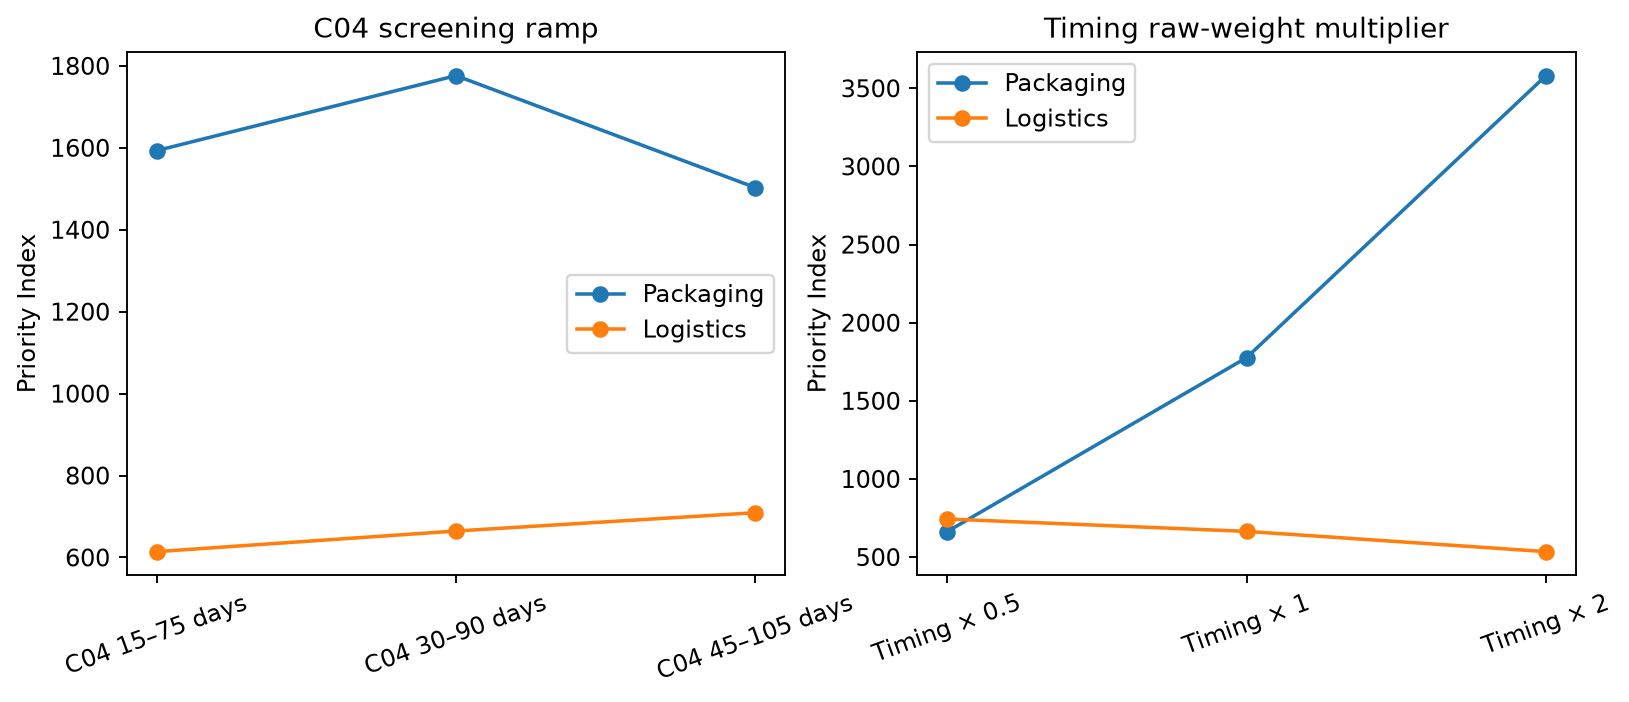

In the declared threshold scenarios, Packaging ranks 1, 1, 1; in the Timing-weight scenarios it ranks 2, 1, 1. Read the accompanying values and overlap columns; stability within these scenarios does not establish universal robustness.

With Timing raw weights multiplied by 0.5, companyID_0000 | Logistics ranks 1, ahead of companyID_0000 | Packaging at rank 2. This is an exploratory weight change outside the three original view definitions; it does not contradict their stable leading group order.

In [22]:
threshold_sensitivity, weight_sensitivity = sensitivity_tables(app)
table(threshold_sensitivity, "C04_threshold_sensitivity", rows=20)
table(weight_sensitivity, "Timing_weight_sensitivity", rows=20)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, frame, title in [
    (axes[0], threshold_sensitivity, "C04 screening ramp"),
    (axes[1], weight_sensitivity, "Timing raw-weight multiplier"),
]:
    for group, sub in frame.groupby("group", sort=False):
        ax.plot(sub["scenario"], sub["PI"], marker="o", label=group.split(" | ")[-1])
    ax.set(title=title, ylabel="Priority Index")
    ax.tick_params(axis="x", rotation=20)
    ax.legend()
figure(fig, "08_exploratory_sensitivity")
report(
    "In the declared threshold scenarios, Packaging ranks "
    + ", ".join(
        str(int(x))
        for x in threshold_sensitivity.loc[
            threshold_sensitivity.group.eq(paper.PACKAGING), "rank"
        ]
    )
    + "; in the Timing-weight scenarios it ranks "
    + ", ".join(
        str(int(x))
        for x in weight_sensitivity.loc[
            weight_sensitivity.group.eq(paper.PACKAGING), "rank"
        ]
    )
    + ". Read the accompanying values and overlap columns; stability within these scenarios does not establish universal robustness."
)
half_timing = weight_sensitivity.loc[
    weight_sensitivity.timing_multiplier.eq(0.5)
].sort_values("rank")
report(
    f"With Timing raw weights multiplied by 0.5, {half_timing.group.iloc[0]} ranks "
    f'{int(half_timing["rank"].iloc[0])}, ahead of {half_timing.group.iloc[1]} '
    f'at rank {int(half_timing["rank"].iloc[1])}. This is an exploratory weight change outside '
    "the three original view definitions; it does not contradict their stable leading group order."
)

## Supplement C. Document and vendor concentration

The cumulative curve measures the share of positive document PI reached in rank order. The vendor table instead sums case penalties within Packaging. These quantities have different denominators and interpretations.

Concentration can inform the scope of record review. It does not measure money, avoidable effort or responsibility for deviations, and it does not establish an optimal review budget.

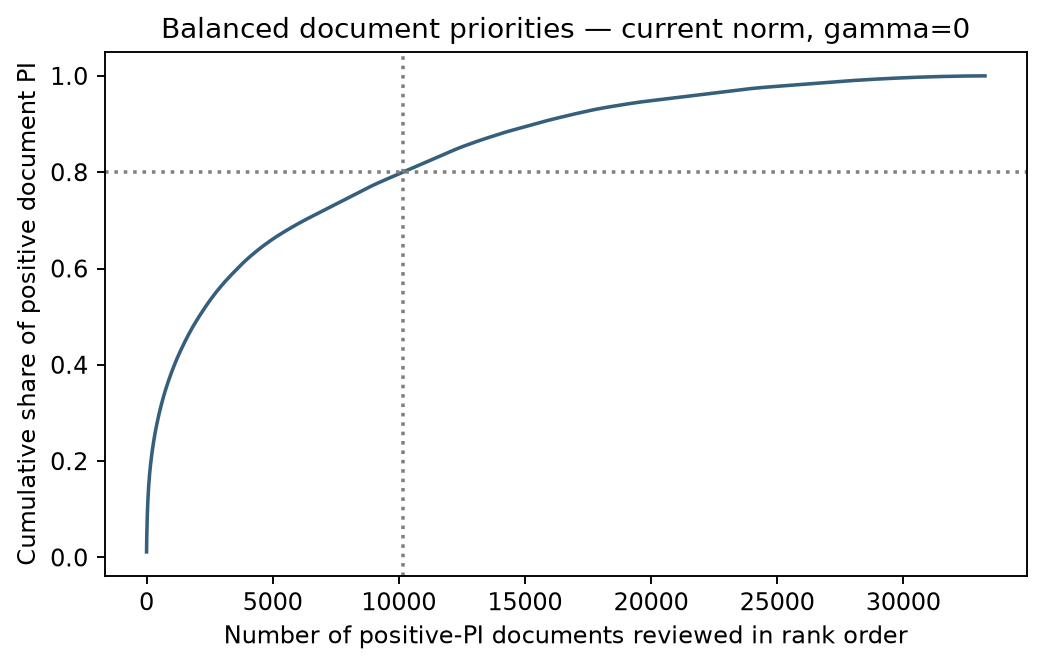

,cases,total_penalty,mean_penalty,cumulative_share
vendor,,,,
vendorID_0136,14369,2269.949281,0.157975,0.176727
vendorID_0120,13449,1858.463140,0.138186,0.321418
vendorID_0104,9773,1399.526639,0.143203,0.430378
vendorID_0182,6794,1002.325094,0.147531,0.508414
vendorID_0103,5813,943.445557,0.162299,0.581866
vendorID_0106,7067,880.145684,0.124543,0.650390
vendorID_0264,3222,312.688812,0.097048,0.674735
vendorID_0167,1526,220.513604,0.144504,0.691903
vendorID_0524,1896,215.912235,0.113878,0.708713


10,156 documents account for at least 80% of positive document PI: 30.56% of 33,237 positive-priority documents, or 13.30% of all 76,349 documents. This is concentration of a configured priority quantity, not proof of a correct review budget.

In [23]:
doc_table = app.backlog("Balanced", by="document").table
positive_docs = doc_table.loc[doc_table.PI.gt(paper.POSITIVE)].copy()
positive_docs["rank"] = np.arange(1, len(positive_docs) + 1)
positive_docs["cumulative_PI_share"] = (
    positive_docs.PI.cumsum() / positive_docs.PI.sum()
)
positive_docs.to_csv(
    OUT / "tables" / "positive_document_priority_concentration.csv.gz",
    compression="gzip",
)
needed80 = int(
    np.searchsorted(positive_docs.cumulative_PI_share.to_numpy(), 0.8, side="left") + 1
)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(positive_docs["rank"], positive_docs.cumulative_PI_share, color="#365f7c")
ax.axhline(0.8, color="grey", ls=":")
ax.axvline(needed80, color="grey", ls=":")
ax.set(
    xlabel="Number of positive-PI documents reviewed in rank order",
    ylabel="Cumulative share of positive document PI",
    title="Balanced document priorities — current norm, gamma=0",
)
figure(fig, "09_document_priority_concentration")
table(paper.vendor_penalties(DATA).head(20), "packaging_vendor_penalty_top20", rows=20)
paper.vendor_penalties(DATA).to_csv(OUT / "tables" / "packaging_vendor_penalty_all.csv")
report(
    f"{needed80:,} documents account for at least 80% of positive document PI: "
    f"{needed80/len(positive_docs):.2%} of {len(positive_docs):,} positive-priority documents, "
    f"or {needed80/len(doc_table):.2%} of all {len(doc_table):,} documents. "
    "This is concentration of a configured priority quantity, not proof of a correct review budget."
)

## Exported results

The final cell saves all PO-item assessments, scores and coverage alongside the configuration and calculation records. Tables and figures are available in `outputs/section_v/`. The run summary records input hashes, package versions, comparison results and the scope of source-record verification.

In [24]:
case_export = pd.concat(
    [
        a.features[["document", "group", "flow", "vendor"]],
        result.scores.add_prefix("score_"),
        pd.DataFrame({v: result.coverage(v) for v in app.views}).add_prefix(
            "coverage_"
        ),
        a.severity.add_prefix("deviation_"),
        a.state.add_prefix("state_"),
    ],
    axis=1,
)
case_export.to_csv(
    OUT / "tables" / "all_PO_item_assessments.csv.gz", compression="gzip"
)
RUN["input_hashes"] = verified.sha256.to_dict()
RUN["printed_values_compared"] = len(comparison)
RUN["printed_values_agree"] = int(comparison.status.eq("agrees").sum())
RUN["printed_values_differ"] = int(comparison.status.eq("differs").sum())
RUN["max_native_reference_residual"] = float(consistency["largest absolute difference"])
RUN["worked_C04_endpoints_interval_and_deviation_reconstructed_from_source"] = True
RUN["worked_case_prepared_contributions_reconcile_with_native_score"] = True
RUN["criterion_and_layer_additivity_verified"] = True
RUN["primary_configuration_unchanged"] = cfg == configuration("bpic2019")
assert RUN["primary_configuration_unchanged"]
(OUT / "provenance" / "run_summary.json").write_text(json.dumps(RUN, indent=2) + "\n")
display(pd.Series(RUN, name="Completed run"))

wise-pm-library                                                                                                                                                        1.0.1
python                                                                                                                                                                3.13.3
numpy                                                                                                                                                                  2.5.4
pandas                                                                                                                                                                 3.0.6
matplotlib                                                                                                                                                            3.11.2
analysis_sha256                                                                                             9256dde9940aae1b69c2cf4c761